In [ ]:
import os
import shutil
from pathlib import Path

print("===== ENVIRONMENT =====")
print("Current directory:", os.getcwd())

print("\n===== GPU =====")
try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU name:", torch.cuda.get_device_name(0))
        print("GPU count:", torch.cuda.device_count())
except Exception as e:
    print("GPU check error:", repr(e))

print("\n===== DISK SPACE =====")
for path in ["/kaggle/input", "/kaggle/working"]:
    if os.path.exists(path):
        usage = shutil.disk_usage(path)
        print(
            path,
            "| Free:",
            round(usage.free / 1024**3, 2),
            "GB"
        )

print("\n===== INPUT DATASETS =====")
input_root = Path("/kaggle/input")

if input_root.exists():
    for item in sorted(input_root.iterdir()):
        print("[DIR]" if item.is_dir() else "[FILE]", item.name)
else:
    print("Input directory not found.")

In [ ]:
from pathlib import Path

root = Path("/kaggle/input")

print("===== INPUT ROOT =====")
print("Path:", root)
print("Exists:", root.exists())

def inspect_tree(folder, depth=0, max_depth=7):
    if depth > max_depth or not folder.is_dir():
        return

    indent = "  " * depth
    subdirs = []
    sample_files = []

    try:
        for item in folder.iterdir():
            if item.is_dir():
                subdirs.append(item)
            elif len(sample_files) < 4:
                sample_files.append(item.name)
    except PermissionError:
        print(indent + "[Permission denied]", folder.name)
        return

    print(f"{indent}[DIR] {folder.name}/")

    for name in sample_files:
        print(f"{indent}  [FILE] {name}")

    if len(subdirs) > 12:
        print(f"{indent}  ... {len(subdirs)} subfolders")

    for subdir in sorted(subdirs, key=lambda p: p.name)[:12]:
        inspect_tree(subdir, depth + 1, max_depth)

print("\n===== DATASET STRUCTURE =====")

for item in sorted(root.iterdir(), key=lambda p: p.name):
    if item.is_dir():
        inspect_tree(item)
    else:
        print("[FILE]", item.name)

In [ ]:
from pathlib import Path

ROOT = Path("/kaggle/input/datasets/solesensei/solesensei_bdd100k")

print("===== DATASET ROOT =====")
print("Path:", ROOT)
print("Exists:", ROOT.exists())

print("\n===== TOP-LEVEL FOLDERS =====")
if ROOT.exists():
    for item in sorted(ROOT.iterdir()):
        kind = "DIR " if item.is_dir() else "FILE"
        print(f"[{kind}] {item.name}")

checks = {
    "100K train images":
        ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "train",

    "100K val images":
        ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "val",

    "10K train images":
        ROOT / "bdd100k" / "bdd100k" / "images" / "10k" / "train",

    "10K val images":
        ROOT / "bdd100k" / "bdd100k" / "images" / "10k" / "val",

    "Train JSON":
        ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
        / "bdd100k_labels_images_train.json",

    "Val JSON":
        ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
        / "bdd100k_labels_images_val.json",

    "Semantic train masks":
        ROOT / "bdd100k_seg" / "bdd100k" / "seg" / "labels" / "train",

    "Semantic val masks":
        ROOT / "bdd100k_seg" / "bdd100k" / "seg" / "labels" / "val",
}

print("\n===== IMPORTANT PATHS =====")

for name, path in checks.items():
    exists = path.exists()
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", exists)

    if exists and path.is_dir():
        entries = list(path.iterdir())
        print("Direct entries:", len(entries))
        for item in entries[:3]:
            print("  ", item.name)
    elif exists and path.is_file():
        print("Size (MB):", round(path.stat().st_size / 1024**2, 2))

In [ ]:
from pathlib import Path
import importlib.util

ROOT = Path("/kaggle/input/datasets/solesensei/solesensei_bdd100k")

IMAGE_ROOT = ROOT / "bdd100k" / "bdd100k" / "images" / "100k"

print("===== RECURSIVE IMAGE COUNTS =====")

for split in ["train", "val", "test"]:
    folder = IMAGE_ROOT / split

    if not folder.exists():
        print(f"{split}: FOLDER NOT FOUND")
        continue

    direct_count = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"}
    )

    recursive_count = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"}
    )

    subfolders = [
        p.name for p in folder.iterdir()
        if p.is_dir()
    ]

    print(f"\nSplit: {split}")
    print(f"Images directly inside folder: {direct_count:,}")
    print(f"Images including subfolders:   {recursive_count:,}")
    print(f"Immediate subfolders: {subfolders}")

print("\n===== JSON STREAMING LIBRARY =====")
print("ijson installed:", importlib.util.find_spec("ijson") is not None)

In [ ]:
!pip -q install ijson

In [ ]:
import ijson

print("ijson da san sang.")

In [ ]:
from pathlib import Path
from collections import Counter
import ijson

ROOT = Path("/kaggle/input/datasets/solesensei/solesensei_bdd100k")

IMAGE_ROOT = ROOT / "bdd100k" / "bdd100k" / "images" / "100k"
JSON_ROOT = ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"

SPLITS = {
    "train": {
        "images": IMAGE_ROOT / "train",
        "json": JSON_ROOT / "bdd100k_labels_images_train.json",
    },
    "val": {
        "images": IMAGE_ROOT / "val",
        "json": JSON_ROOT / "bdd100k_labels_images_val.json",
    },
}

# Eight target object classes for instance segmentation.
TARGET_CLASSES = {
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motor",
    "bike",
}

def inspect_split(split, image_dir, json_path):
    print("\n" + "=" * 65)
    print(f"SPLIT: {split}")

    if not image_dir.is_dir():
        print("ERROR: Image directory not found:", image_dir)
        return

    if not json_path.is_file():
        print("ERROR: JSON file not found:", json_path)
        return

    print("Indexing image paths...")

    image_paths = {}
    duplicate_names = 0

    for path in image_dir.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in {".jpg", ".jpeg"}:
            continue

        key = path.name.lower()

        if key in image_paths:
            duplicate_names += 1
        else:
            image_paths[key] = path

    print("Unique image names:", f"{len(image_paths):,}")
    print("Duplicate filenames:", duplicate_names)

    matched_names = set()
    object_counts = Counter()
    candidate_samples = []
    record_count = 0

    print("Reading JSON records...")

    with json_path.open("rb") as f:
        for record in ijson.items(f, "item"):
            record_count += 1
            name = record.get("name")

            if not isinstance(name, str):
                continue

            image_path = image_paths.get(name.lower())

            if image_path is None:
                continue

            matched_names.add(name.lower())
            valid_boxes = []

            for label in record.get("labels") or []:
                category = label.get("category")
                box = label.get("box2d")

                if category not in TARGET_CLASSES or not isinstance(box, dict):
                    continue

                try:
                    x1 = float(box["x1"])
                    y1 = float(box["y1"])
                    x2 = float(box["x2"])
                    y2 = float(box["y2"])
                except (KeyError, TypeError, ValueError):
                    continue

                if x2 <= x1 or y2 <= y1:
                    continue

                object_counts[category] += 1
                valid_boxes.append({
                    "class": category,
                    "box": [x1, y1, x2, y2],
                })

            # Keep a few manageable examples containing at least one car.
            car_count = sum(b["class"] == "car" for b in valid_boxes)

            if (
                split == "train"
                and 1 <= car_count <= 3
                and 1 <= len(valid_boxes) <= 6
                and len(candidate_samples) < 8
            ):
                candidate_samples.append({
                    "name": name,
                    "path": str(image_path),
                    "boxes": valid_boxes,
                })

            if record_count % 10000 == 0:
                print(f"Scanned {record_count:,} JSON records...")

    print("\n----- MATCH SUMMARY -----")
    print("JSON records:", f"{record_count:,}")
    print("Matched images:", f"{len(matched_names):,}")
    print("Images without matched JSON:", f"{len(image_paths) - len(matched_names):,}")

    print("\n----- TARGET OBJECT COUNTS -----")
    for category in sorted(TARGET_CLASSES):
        print(f"{category:12s}: {object_counts[category]:,}")

    if split == "train":
        print("\n----- SAMPLE IMAGES FOR SAM TEST -----")
        for i, sample in enumerate(candidate_samples, start=1):
            categories = [b["class"] for b in sample["boxes"]]
            print(f"\nSample {i}: {sample['name']}")
            print("Path:", sample["path"])
            print("Target boxes:", len(sample["boxes"]))
            print("Classes:", categories)

        if not candidate_samples:
            print("No suitable sample images found.")

for split, paths in SPLITS.items():
    inspect_split(split, paths["images"], paths["json"])

print("\nInspection complete. No files were modified.")

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import ijson

ROOT = Path("/kaggle/input/datasets/solesensei/solesensei_bdd100k")

IMAGE_ROOT = ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "train"
JSON_PATH = (
    ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
    / "bdd100k_labels_images_train.json"
)

SAMPLE_NAMES = [
    "0000f77c-6257be58.jpg",
    "0001542f-7c670be8.jpg",
    "00067cfb-caba8a02.jpg",
    "002d290d-89d1aea8.jpg",
]

TARGET_CLASSES = {
    "person", "rider", "car", "truck",
    "bus", "train", "motor", "bike"
}

COLORS = {
    "person": "yellow",
    "rider": "orange",
    "car": "lime",
    "truck": "cyan",
    "bus": "magenta",
    "train": "white",
    "motor": "orange",
    "bike": "yellow",
}

print("Tim duong dan anh mau...")
image_paths = {
    p.name: p
    for p in IMAGE_ROOT.rglob("*.jpg")
    if p.name in SAMPLE_NAMES
}

print(f"Tim thay {len(image_paths)}/{len(SAMPLE_NAMES)} anh.")

print("Doc nhan tu JSON...")
annotations = {}

with JSON_PATH.open("rb") as f:
    for record in ijson.items(f, "item"):
        if record.get("name") not in SAMPLE_NAMES:
            continue

        annotations[record["name"]] = [
            label for label in (record.get("labels") or [])
            if label.get("category") in TARGET_CLASSES
            and isinstance(label.get("box2d"), dict)
        ]

        if len(annotations) == len(SAMPLE_NAMES):
            break

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, name in zip(axes, SAMPLE_NAMES):
    ax.axis("off")

    if name not in image_paths:
        ax.set_title(f"Khong tim thay anh: {name}")
        continue

    with Image.open(image_paths[name]) as source:
        image = source.convert("RGB")

    draw = ImageDraw.Draw(image)
    width, height = image.size

    boxes = annotations.get(name, [])

    for label in boxes:
        box = label["box2d"]

        try:
            x1, y1, x2, y2 = [
                float(box[k]) for k in ("x1", "y1", "x2", "y2")
            ]
        except (KeyError, TypeError, ValueError):
            continue

        if x2 <= x1 or y2 <= y1:
            continue

        x1 = max(0, min(width - 1, round(x1)))
        x2 = max(0, min(width - 1, round(x2)))
        y1 = max(0, min(height - 1, round(y1)))
        y2 = max(0, min(height - 1, round(y2)))

        if x2 <= x1 or y2 <= y1:
            continue

        category = label["category"]
        color = COLORS.get(category, "white")

        draw.rectangle(
            [x1, y1, x2, y2],
            outline=color,
            width=3,
        )

        draw.text(
            (x1, max(0, y1 - 15)),
            category,
            fill=color,
            stroke_width=2,
            stroke_fill="black",
        )

    ax.imshow(image)
    ax.set_title(
        f"{name}\nBoxes: {len(boxes)} | Image: {width}x{height}",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

print("\nHoan tat. Day la bounding boxes tu JSON, chua phai mask SAM.")

In [ ]:
import torch
import importlib.util

print("===== GPU CHECK =====")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
    print(
        "GPU 0 memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

print("\n===== ULTRALYTICS CHECK =====")
print("Ultralytics installed:", importlib.util.find_spec("ultralytics") is not None)

if importlib.util.find_spec("ultralytics") is not None:
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)

    try:
        from ultralytics import SAM
        print("SAM import: OK")
    except Exception as e:
        print("SAM import failed:", repr(e))

In [ ]:
%pip install -q ultralytics

In [ ]:
import torch
import ultralytics
from ultralytics import SAM

print("===== LIBRARY CHECK =====")
print("Ultralytics version:", ultralytics.__version__)
print("SAM import: OK")

print("\n===== GPU CHECK =====")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())

In [ ]:
import torch
from pathlib import Path
from ultralytics import SAM

print("===== CHECK GPU =====")
assert torch.cuda.is_available(), "GPU chua san sang!"

print("GPU:", torch.cuda.get_device_name(0))

print("\n===== LOADING SAM =====")
print("Neu chua co trong cache, he thong se tai sam_b.pt.")

sam = SAM("sam_b.pt")

print("\n===== SAM READY =====")
print("Model type:", type(sam).__name__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

In [ ]:

from pathlib import Path

import ijson
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

from ultralytics import SAM

# --------------------------------------------------
# 1. Dataset paths
# --------------------------------------------------
ROOT = Path("/kaggle/input/datasets/solesensei/solesensei_bdd100k")

IMAGE_ROOT = ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "train"

JSON_PATH = (
    ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
    / "bdd100k_labels_images_train.json"
)

SAMPLE_NAMES = [
    "0000f77c-6257be58.jpg",
    "0001542f-7c670be8.jpg",
    "00067cfb-caba8a02.jpg",
    "002d290d-89d1aea8.jpg",
]

TARGET_CLASSES = {
    "person", "rider", "car", "truck",
    "bus", "train", "motor", "bike",
}

# --------------------------------------------------
# 2. Load SAM if it is not already in memory
# --------------------------------------------------
if "sam" not in globals():
    sam = SAM("sam_b.pt")

print("GPU:", __import__("torch").cuda.get_device_name(0))

# --------------------------------------------------
# 3. Find sample images
# --------------------------------------------------
sample_paths = {}

for path in IMAGE_ROOT.rglob("*.jpg"):
    if path.name in SAMPLE_NAMES:
        sample_paths[path.name] = path

print(f"Found {len(sample_paths)}/{len(SAMPLE_NAMES)} sample images.")

# --------------------------------------------------
# 4. Read boxes from the JSON file
# --------------------------------------------------
annotations = {}

with JSON_PATH.open("rb") as f:
    for record in ijson.items(f, "item"):
        name = record.get("name")

        if name not in SAMPLE_NAMES:
            continue

        boxes = []

        for label in record.get("labels") or []:
            category = label.get("category")
            box = label.get("box2d")

            if category not in TARGET_CLASSES or not isinstance(box, dict):
                continue

            try:
                x1, y1, x2, y2 = [
                    float(box[k]) for k in ("x1", "y1", "x2", "y2")
                ]
            except (KeyError, TypeError, ValueError):
                continue

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append({
                "category": category,
                "xyxy": [x1, y1, x2, y2],
            })

        annotations[name] = boxes

        if len(annotations) == len(SAMPLE_NAMES):
            break

# --------------------------------------------------
# 5. Run SAM and visualize predicted masks
# --------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, name in zip(axes, SAMPLE_NAMES):
    ax.axis("off")

    if name not in sample_paths:
        ax.set_title(f"Image not found: {name}")
        continue

    image_path = sample_paths[name]

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    width, height = image.size
    image_np = np.asarray(image)

    boxes = annotations.get(name, [])

    if not boxes:
        ax.imshow(image_np)
        ax.set_title(f"{name}\nNo target boxes found")
        continue

    # Clamp boxes to image boundaries.
    valid_boxes = []

    for item in boxes:
        x1, y1, x2, y2 = item["xyxy"]

        x1 = float(np.clip(x1, 0, width - 1))
        x2 = float(np.clip(x2, 0, width - 1))
        y1 = float(np.clip(y1, 0, height - 1))
        y2 = float(np.clip(y2, 0, height - 1))

        if x2 > x1 and y2 > y1:
            valid_boxes.append({
                "category": item["category"],
                "xyxy": [x1, y1, x2, y2],
            })

    if not valid_boxes:
        ax.imshow(image_np)
        ax.set_title(f"{name}\nNo valid boxes")
        continue

    bboxes = [item["xyxy"] for item in valid_boxes]

    print(f"Running SAM: {name} | {len(bboxes)} boxes")

    results = sam.predict(
        source=str(image_path),
        bboxes=bboxes,
        device=0,
        imgsz=1024,
        verbose=False,
    )

    result = results[0]
    ax.imshow(image_np)

    masks = None

    if result.masks is not None:
        masks = result.masks.data.detach().cpu().numpy()

    if masks is None:
        print("Warning: SAM returned no masks for", name)
        mask_count = 0
    else:
        mask_count = len(masks)

        # Overlay each mask using a different color.
        for i, mask in enumerate(masks):
            if mask.shape != (height, width):
                mask_img = Image.fromarray(
                    (mask > 0.5).astype(np.uint8) * 255
                )
                mask = np.asarray(
                    mask_img.resize(
                        (width, height),
                        Image.Resampling.NEAREST,
                    )
                ) > 0
            else:
                mask = mask > 0.5

            color = plt.get_cmap("tab10")(i % 10)

            overlay = np.zeros((height, width, 4), dtype=np.float32)
            overlay[mask, :3] = color[:3]
            overlay[mask, 3] = 0.38

            ax.imshow(overlay)

    # Draw original JSON boxes over the masks.
    for i, item in enumerate(valid_boxes):
        x1, y1, x2, y2 = item["xyxy"]
        category = item["category"]
        color = plt.get_cmap("tab10")(i % 10)

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=color,
                linewidth=1.5,
            )
        )

        ax.text(
            x1,
            max(0, y1 - 5),
            category,
            color="white",
            fontsize=8,
            bbox={"facecolor": color, "alpha": 0.85, "pad": 2},
        )

    ax.set_title(
        f"{name}\nJSON boxes: {len(valid_boxes)} | SAM masks: {mask_count}",
        fontsize=9,
    )

    print(f"Finished: {name} | Masks returned: {mask_count}")

plt.tight_layout()
plt.show()

print("\nSAM sample inference completed.")
print("No YOLO label files were created in this step.")


In [ ]:

from pathlib import Path
from collections import Counter
import shutil

import cv2
import ijson
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import SAM

# --------------------------------------------------
# 1. Paths and class IDs
# --------------------------------------------------
ROOT = Path("/kaggle/input/datasets/solesensei/solesensei_bdd100k")

IMAGE_ROOT = ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "train"
JSON_PATH = (
    ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
    / "bdd100k_labels_images_train.json"
)

OUT = Path("/kaggle/working/bdd100k_instance_pilot")
OUT_IMAGES = OUT / "images" / "train"
OUT_LABELS = OUT / "labels" / "train"
OUT_PREVIEWS = OUT / "previews"

for folder in (OUT_IMAGES, OUT_LABELS, OUT_PREVIEWS):
    folder.mkdir(parents=True, exist_ok=True)

# Fixed class-ID mapping. Keep this mapping unchanged in later stages.
CLASS_TO_ID = {
    "person": 0,
    "rider": 1,
    "car": 2,
    "truck": 3,
    "bus": 4,
    "train": 5,
    "motor": 6,
    "bike": 7,
}

SAMPLE_NAMES = [
    "0000f77c-6257be58.jpg",
    "0001542f-7c670be8.jpg",
    "00067cfb-caba8a02.jpg",
    "00202076-7a95b4e3.jpg",
    "002d290d-89d1aea8.jpg",
    "002d290d-fa2a8964.jpg",
    "0035afff-434368a1.jpg",
    "00391a82-d1428e56.jpg",
]

# --------------------------------------------------
# 2. Check dependencies and SAM
# --------------------------------------------------
import torch

assert torch.cuda.is_available(), "CUDA/GPU is unavailable."

if "sam" not in globals():
    sam = SAM("sam_b.pt")

print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUT)

# --------------------------------------------------
# 3. Find paths to the eight sample images
# --------------------------------------------------
print("\nIndexing sample images...")

image_paths = {}

for path in IMAGE_ROOT.rglob("*.jpg"):
    if path.name in SAMPLE_NAMES:
        image_paths[path.name] = path

print(f"Found {len(image_paths)}/{len(SAMPLE_NAMES)} images.")

# --------------------------------------------------
# 4. Read their bounding boxes from the JSON
# --------------------------------------------------
annotations = {}

with JSON_PATH.open("rb") as f:
    for record in ijson.items(f, "item"):
        name = record.get("name")

        if name not in SAMPLE_NAMES:
            continue

        boxes = []

        for label in record.get("labels") or []:
            category = label.get("category")
            box = label.get("box2d")

            if category not in CLASS_TO_ID or not isinstance(box, dict):
                continue

            try:
                x1, y1, x2, y2 = [
                    float(box[k]) for k in ("x1", "y1", "x2", "y2")
                ]
            except (KeyError, TypeError, ValueError):
                continue

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append({
                "category": category,
                "class_id": CLASS_TO_ID[category],
                "xyxy": [x1, y1, x2, y2],
            })

        annotations[name] = boxes

        if len(annotations) == len(SAMPLE_NAMES):
            break

# --------------------------------------------------
# 5. Convert binary masks into YOLO segmentation polygons
# --------------------------------------------------
def mask_to_yolo_polygon(mask, width, height):
    """Return one normalized polygon from the largest external contour."""
    mask = (mask > 0.5).astype(np.uint8)

    if mask.shape != (height, width):
        mask = cv2.resize(
            mask,
            (width, height),
            interpolation=cv2.INTER_NEAREST,
        )

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )

    if not contours:
        return None

    contour = max(contours, key=cv2.contourArea)

    if cv2.contourArea(contour) < 2:
        return None

    perimeter = cv2.arcLength(contour, True)
    epsilon = max(1.0, 0.002 * perimeter)

    contour = cv2.approxPolyDP(contour, epsilon, True)
    points = contour.reshape(-1, 2)

    if len(points) < 3:
        return None

    normalized = []

    for x, y in points:
        normalized.extend([
            float(np.clip(x / width, 0.0, 1.0)),
            float(np.clip(y / height, 0.0, 1.0)),
        ])

    return normalized


# --------------------------------------------------
# 6. Run SAM, save images and label files
# --------------------------------------------------
summary = []
preview_items = []

for image_number, name in enumerate(SAMPLE_NAMES, start=1):
    if name not in image_paths:
        print("SKIP: image missing:", name)
        continue

    boxes = annotations.get(name, [])

    if not boxes:
        print("SKIP: no supported bounding boxes:", name)
        continue

    image_path = image_paths[name]

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    width, height = image.size
    valid_boxes = []

    for item in boxes:
        x1, y1, x2, y2 = item["xyxy"]

        x1 = np.clip(x1, 0, width - 1)
        y1 = np.clip(y1, 0, height - 1)
        x2 = np.clip(x2, 0, width - 1)
        y2 = np.clip(y2, 0, height - 1)

        if x2 > x1 and y2 > y1:
            valid_boxes.append({
                **item,
                "xyxy": [float(x1), float(y1), float(x2), float(y2)],
            })

    if not valid_boxes:
        print("SKIP: no valid boxes after clipping:", name)
        continue

    print(
        f"\n[{image_number}/{len(SAMPLE_NAMES)}] "
        f"{name} — {len(valid_boxes)} boxes"
    )

    result = sam.predict(
        source=str(image_path),
        bboxes=[item["xyxy"] for item in valid_boxes],
        device=0,
        imgsz=1024,
        verbose=False,
    )[0]

    masks = (
        result.masks.data.detach().cpu().numpy()
        if result.masks is not None
        else None
    )

    if masks is None or len(masks) != len(valid_boxes):
        print("SKIP: mask count does not match box count.")
        print(
            "Boxes:",
            len(valid_boxes),
            "| Masks:",
            0 if masks is None else len(masks),
        )
        continue

    label_lines = []
    accepted_masks = []
    accepted_classes = []

    for item, mask in zip(valid_boxes, masks):
        polygon = mask_to_yolo_polygon(mask, width, height)

        if polygon is None:
            continue

        coords = " ".join(f"{v:.6f}" for v in polygon)
        label_lines.append(f"{item['class_id']} {coords}")
        accepted_masks.append(mask)
        accepted_classes.append(item["category"])

    if not label_lines:
        print("SKIP: no usable polygons.")
        continue

    # Copy original image to writable output.
    output_image = OUT_IMAGES / name
    shutil.copy2(image_path, output_image)

    # One line per object, in YOLO segmentation format.
    output_label = OUT_LABELS / f"{Path(name).stem}.txt"
    output_label.write_text(
        "\n".join(label_lines) + "\n",
        encoding="utf-8",
    )

    # Save a colored preview for quality inspection.
    display_image = np.asarray(image).copy()
    overlay = display_image.copy()

    for i, mask in enumerate(accepted_masks):
        mask = (mask > 0.5).astype(np.uint8)

        if mask.shape != (height, width):
            mask = cv2.resize(
                mask,
                (width, height),
                interpolation=cv2.INTER_NEAREST,
            )

        color = np.array(
            plt.get_cmap("tab10")(i % 10)[:3]
        ) * 255
        color = color.astype(np.uint8)

        overlay[mask > 0] = (
            0.55 * overlay[mask > 0] + 0.45 * color
        ).astype(np.uint8)

    preview_path = OUT_PREVIEWS / name
    Image.fromarray(overlay).save(preview_path)

    preview_items.append((name, overlay))
    summary.append({
        "image": name,
        "boxes": len(valid_boxes),
        "masks": len(masks),
        "polygons": len(label_lines),
        "label_file": str(output_label),
    })

    print(
        f"Saved: {output_label.name} | "
        f"Boxes={len(valid_boxes)}, "
        f"Masks={len(masks)}, "
        f"Polygons={len(label_lines)}"
    )

# --------------------------------------------------
# 7. Display previews
# --------------------------------------------------
if preview_items:
    cols = 2
    rows = (len(preview_items) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.atleast_1d(axes).reshape(-1)

    for ax, (name, overlay) in zip(axes, preview_items):
        ax.imshow(overlay)
        ax.set_title(name, fontsize=9)
        ax.axis("off")

    for ax in axes[len(preview_items):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("\n===== PILOT SUMMARY =====")
print("Images saved:", len(summary))
print("Output directory:", OUT)

for item in summary:
    print(item)

print("\nThis is a pilot only. No full-scale dataset was generated.")


In [ ]:
from pathlib import Path
from collections import Counter
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from PIL import Image

OUT = Path("/kaggle/working/bdd100k_instance_pilot")
IMG_DIR = OUT / "images" / "train"
LBL_DIR = OUT / "labels" / "train"

CLASS_NAMES = [
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motorcycle",
    "bicycle",
]

print("===== OUTPUT CHECK =====")
print("Output exists:", OUT.exists())
print("Images folder exists:", IMG_DIR.exists())
print("Labels folder exists:", LBL_DIR.exists())

if not IMG_DIR.is_dir() or not LBL_DIR.is_dir():
    raise FileNotFoundError(
        "Khong tim thay thu muc images/train hoac labels/train."
    )

images = {p.stem: p for p in IMG_DIR.glob("*.jpg")}
labels = {p.stem: p for p in LBL_DIR.glob("*.txt")}

print("\nSaved images:", len(images))
print("Saved label files:", len(labels))
print("Images without label files:", len(set(images) - set(labels)))
print("Label files without images:", len(set(labels) - set(images)))

class_counts = Counter()
invalid_rows = []
total_polygons = 0
empty_labels = []

for stem, label_path in sorted(labels.items()):
    text = label_path.read_text(encoding="utf-8").strip()

    if not text:
        empty_labels.append(stem)
        continue

    for line_no, line in enumerate(text.splitlines(), start=1):
        parts = line.split()

        try:
            if len(parts) < 7:
                raise ValueError("Polygon co it hon 3 dinh")

            class_id = int(parts[0])
            coords = np.array(
                [float(v) for v in parts[1:]],
                dtype=np.float64,
            )

            if not 0 <= class_id < len(CLASS_NAMES):
                raise ValueError("Class ID ngoai pham vi")

            if len(coords) % 2 != 0:
                raise ValueError("So toa do khong chan")

            if not np.isfinite(coords).all():
                raise ValueError("Toa do khong huu han")

            if ((coords < 0) | (coords > 1)).any():
                raise ValueError("Toa do ngoai khoang 0..1")

            class_counts[CLASS_NAMES[class_id]] += 1
            total_polygons += 1

        except Exception as exc:
            invalid_rows.append(
                (label_path.name, line_no, str(exc))
            )

print("\n===== LABEL VALIDATION =====")
print("Total polygons:", total_polygons)
print("Invalid rows:", len(invalid_rows))
print("Empty label files:", len(empty_labels))
print("Polygons per class:")

for name in CLASS_NAMES:
    print(f"  {name:12s}: {class_counts[name]}")

if invalid_rows:
    print("\nExamples of invalid rows:")
    for item in invalid_rows[:10]:
        print(item)

if empty_labels:
    print("\nEmpty label files:")
    print(empty_labels[:10])

# --------------------------------------------------
# Draw polygons reconstructed from the saved YOLO TXT.
# --------------------------------------------------
print("\n===== PREVIEW EXPORTED POLYGONS =====")

sample_stems = [
    "0000f77c-6257be58",
    "0001542f-7c670be8",
    "00067cfb-caba8a02",
    "002d290d-89d1aea8",
]

colors = plt.get_cmap("tab10")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, stem in zip(axes, sample_stems):
    ax.axis("off")

    if stem not in images:
        ax.set_title(f"Image not found: {stem}")
        continue

    if stem not in labels:
        ax.set_title(f"Label not found: {stem}")
        continue

    with Image.open(images[stem]) as source:
        image = source.convert("RGB")

    width, height = image.size
    ax.imshow(image)

    label_text = labels[stem].read_text(
        encoding="utf-8"
    ).strip()

    polygon_count = 0

    for line in label_text.splitlines():
        parts = line.split()

        if len(parts) < 7:
            continue

        class_id = int(parts[0])
        coords = np.asarray(
            [float(v) for v in parts[1:]],
            dtype=np.float64,
        ).reshape(-1, 2)

        coords[:, 0] *= width
        coords[:, 1] *= height

        color = colors(class_id % 10)

        patch = Polygon(
            coords,
            closed=True,
            fill=False,
            edgecolor=color,
            linewidth=2,
        )
        ax.add_patch(patch)

        ax.text(
            coords[0, 0],
            coords[0, 1],
            CLASS_NAMES[class_id],
            color="white",
            fontsize=8,
            bbox={"facecolor": color, "alpha": 0.8, "pad": 2},
        )

        polygon_count += 1

    ax.set_title(f"{stem}.jpg | Polygons: {polygon_count}")

plt.tight_layout()
plt.show()

print("\n===== AUDIT COMPLETE =====")

In [ ]:

from pathlib import Path
from collections import Counter
import csv
import random
import shutil

import cv2
import ijson
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import SAM
import torch

# ==================================================
# 1. Paths and settings
# ==================================================
ROOT = Path("/kaggle/input/datasets/solesensei/solesensei_bdd100k")

IMAGE_ROOT = ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "train"
JSON_PATH = (
    ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
    / "bdd100k_labels_images_train.json"
)

OUT = Path("/kaggle/working/bdd100k_pilot100")
OUT_IMAGES = OUT / "images" / "train"
OUT_LABELS = OUT / "labels" / "train"
OUT_PREVIEWS = OUT / "previews"

for folder in (OUT_IMAGES, OUT_LABELS, OUT_PREVIEWS):
    folder.mkdir(parents=True, exist_ok=True)

MAX_IMAGES = 100
RANDOM_SEED = 2026

CLASS_TO_ID = {
    "person": 0,
    "rider": 1,
    "car": 2,
    "truck": 3,
    "bus": 4,
    "train": 5,
    "motor": 6,
    "bike": 7,
}

CLASS_NAMES = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle",
]

TARGET_CLASSES = set(CLASS_TO_ID)

assert torch.cuda.is_available(), "GPU khong kha dung."

if "sam" not in globals():
    sam = SAM("sam_b.pt")

print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUT)

# ==================================================
# 2. Index image paths, including nested folders
# ==================================================
print("\nIndexing training images...")

image_paths = {}

for p in IMAGE_ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"}:
        image_paths[p.name.lower()] = p

print("Unique images:", f"{len(image_paths):,}")

# ==================================================
# 3. Randomly sample 100 annotated images
#    Reservoir sampling avoids loading the whole JSON
#    or storing all candidate annotations in RAM.
# ==================================================
rng = random.Random(RANDOM_SEED)
reservoir = []
candidate_count = 0

print("\nScanning JSON and sampling eligible images...")

with JSON_PATH.open("rb") as f:
    for record_number, record in enumerate(ijson.items(f, "item"), start=1):
        name = record.get("name")

        if not isinstance(name, str) or name.lower() not in image_paths:
            continue

        boxes = []

        for label in record.get("labels") or []:
            category = label.get("category")
            box = label.get("box2d")

            if category not in TARGET_CLASSES or not isinstance(box, dict):
                continue

            try:
                x1, y1, x2, y2 = [
                    float(box[k]) for k in ("x1", "y1", "x2", "y2")
                ]
            except (KeyError, TypeError, ValueError):
                continue

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append({
                "category": category,
                "class_id": CLASS_TO_ID[category],
                "xyxy": [x1, y1, x2, y2],
            })

        if not boxes:
            continue

        candidate_count += 1

        item = {
            "name": name,
            "path": image_paths[name.lower()],
            "boxes": boxes,
        }

        if len(reservoir) < MAX_IMAGES:
            reservoir.append(item)
        else:
            j = rng.randrange(candidate_count)
            if j < MAX_IMAGES:
                reservoir[j] = item

        if record_number % 10000 == 0:
            print(f"Scanned {record_number:,} JSON records...")

print("Eligible matched images:", f"{candidate_count:,}")
print("Selected for this pilot:", len(reservoir))

# ==================================================
# 4. Convert each SAM mask into a YOLO polygon
# ==================================================
def mask_to_polygon(mask, width, height):
    mask = (mask > 0.5).astype(np.uint8)

    if mask.shape != (height, width):
        mask = cv2.resize(
            mask, (width, height),
            interpolation=cv2.INTER_NEAREST
        )

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return None

    # Use the largest external contour for this initial pilot.
    contour = max(contours, key=cv2.contourArea)

    if cv2.contourArea(contour) < 2:
        return None

    perimeter = cv2.arcLength(contour, True)
    contour = cv2.approxPolyDP(
        contour, max(1.0, 0.002 * perimeter), True
    )

    points = contour.reshape(-1, 2)

    if len(points) < 3:
        return None

    points = points.astype(np.float64)
    points[:, 0] /= width
    points[:, 1] /= height
    points = np.clip(points, 0.0, 1.0)

    return points

# ==================================================
# 5. Run SAM and save images, YOLO labels, and audit
# ==================================================
audit_rows = []
preview_items = []
saved_images = 0
skipped_images = 0
total_boxes = 0
total_polygons = 0

for image_index, item in enumerate(reservoir, start=1):
    name = item["name"]
    image_path = item["path"]

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    width, height = image.size
    valid_boxes = []

    for box_item in item["boxes"]:
        x1, y1, x2, y2 = box_item["xyxy"]

        x1 = float(np.clip(x1, 0, width - 1))
        x2 = float(np.clip(x2, 0, width - 1))
        y1 = float(np.clip(y1, 0, height - 1))
        y2 = float(np.clip(y2, 0, height - 1))

        if x2 > x1 and y2 > y1:
            valid_boxes.append({
                **box_item,
                "xyxy": [x1, y1, x2, y2],
            })

    if not valid_boxes:
        skipped_images += 1
        continue

    try:
        result = sam.predict(
            source=str(image_path),
            bboxes=[b["xyxy"] for b in valid_boxes],
            device=0,
            imgsz=1024,
            verbose=False,
        )[0]
    except Exception as e:
        print(f"ERROR on {name}: {e}")
        skipped_images += 1
        continue

    if result.masks is None or len(result.masks.data) != len(valid_boxes):
        print(f"SKIP: mask count mismatch for {name}")
        skipped_images += 1
        continue

    masks = result.masks.data.detach().cpu().numpy()

    if result.boxes is not None and result.boxes.conf is not None:
        scores = result.boxes.conf.detach().cpu().numpy()
    else:
        scores = np.full(len(masks), np.nan)

    label_lines = []
    overlay = np.asarray(image).copy()
    visual = overlay.copy()

    for object_index, (box_item, mask, score) in enumerate(
        zip(valid_boxes, masks, scores)
    ):
        polygon = mask_to_polygon(mask, width, height)

        if polygon is None:
            audit_rows.append({
                "image": name,
                "class": box_item["category"],
                "sam_score": float(score),
                "box_area_ratio": "",
                "polygon_points": 0,
                "status": "rejected_empty_or_tiny_mask",
            })
            continue

        coords = " ".join(f"{v:.6f}" for v in polygon.flatten())
        label_lines.append(f"{box_item['class_id']} {coords}")

        # Basic diagnostic: mask area divided by bounding-box area.
        binary_mask = (mask > 0.5).astype(np.uint8)

        if binary_mask.shape != (height, width):
            binary_mask = cv2.resize(
                binary_mask, (width, height),
                interpolation=cv2.INTER_NEAREST
            )

        x1, y1, x2, y2 = box_item["xyxy"]
        box_area = max(1.0, (x2 - x1) * (y2 - y1))
        area_ratio = float(binary_mask.sum() / box_area)

        audit_rows.append({
            "image": name,
            "class": box_item["category"],
            "sam_score": float(score),
            "box_area_ratio": area_ratio,
            "polygon_points": len(polygon),
            "status": "exported",
        })

        color = (
            np.array(plt.get_cmap("tab10")(object_index % 10)[:3]) * 255
        ).astype(np.uint8)

        visual[binary_mask > 0] = (
            0.55 * visual[binary_mask > 0] + 0.45 * color
        ).astype(np.uint8)

    if not label_lines:
        skipped_images += 1
        continue

    # Save only images with at least one valid polygon.
    shutil.copy2(image_path, OUT_IMAGES / name)
    (OUT_LABELS / f"{Path(name).stem}.txt").write_text(
        "\n".join(label_lines) + "\n",
        encoding="utf-8",
    )

    saved_images += 1
    total_boxes += len(valid_boxes)
    total_polygons += len(label_lines)

    if len(preview_items) < 12:
        preview_items.append((name, visual))

    if image_index % 10 == 0 or image_index == len(reservoir):
        print(
            f"Processed {image_index}/{len(reservoir)} | "
            f"Saved images: {saved_images} | "
            f"Polygons: {total_polygons}"
        )

# Save a CSV report for later quality filtering.
report_path = OUT / "mask_quality_report.csv"

with report_path.open("w", newline="", encoding="utf-8") as f:
    fieldnames = [
        "image", "class", "sam_score",
        "box_area_ratio", "polygon_points", "status"
    ]
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(audit_rows)

# Display up to 12 previews.
if preview_items:
    cols = 2
    rows = (len(preview_items) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.atleast_1d(axes).reshape(-1)

    for ax, (name, visual) in zip(axes, preview_items):
        ax.imshow(visual)
        ax.set_title(name, fontsize=9)
        ax.axis("off")

    for ax in axes[len(preview_items):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("\n===== PILOT 100 SUMMARY =====")
print("Eligible matched images:", candidate_count)
print("Selected images:", len(reservoir))
print("Images saved:", saved_images)
print("Images skipped:", skipped_images)
print("Input boxes processed:", total_boxes)
print("Polygons exported:", total_polygons)
print("Image output directory:", OUT_IMAGES)
print("Label output directory:", OUT_LABELS)
print("Quality report:", report_path)


In [ ]:
from pathlib import Path
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from PIL import Image

OUT = Path("/kaggle/working/bdd100k_pilot100")
IMG_DIR = OUT / "images" / "train"
LBL_DIR = OUT / "labels" / "train"

CLASS_NAMES = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle",
]

# Class IDs worth checking for people and two-wheelers.
TARGET_IDS = {0, 1, 6, 7}

candidates = []

for label_path in sorted(LBL_DIR.glob("*.txt")):
    lines = label_path.read_text(encoding="utf-8").splitlines()

    parsed = []
    for line in lines:
        parts = line.split()

        if len(parts) < 7:
            continue

        try:
            class_id = int(parts[0])
            coords = np.asarray(
                [float(v) for v in parts[1:]],
                dtype=np.float64,
            ).reshape(-1, 2)
        except (ValueError, IndexError):
            continue

        if class_id not in range(len(CLASS_NAMES)):
            continue

        if len(coords) < 3 or not np.isfinite(coords).all():
            continue

        parsed.append((class_id, coords))

    if any(class_id in TARGET_IDS for class_id, _ in parsed):
        image_path = IMG_DIR / f"{label_path.stem}.jpg"

        if image_path.exists():
            candidates.append((image_path, label_path, parsed))

print("Pilot images containing people or two-wheelers:", len(candidates))

if not candidates:
    print(
        "No matching images found. This random pilot may not contain "
        "the target classes."
    )
else:
    # Show up to 12 images to keep the output manageable.
    selected = candidates[:12]

    cols = 2
    rows = math.ceil(len(selected) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.atleast_1d(axes).reshape(-1)

    colors = plt.get_cmap("tab10")

    for ax, (image_path, label_path, parsed) in zip(axes, selected):
        with Image.open(image_path) as im:
            image = im.convert("RGB")

        width, height = image.size
        ax.imshow(image)

        for class_id, coords in parsed:
            points = coords.copy()
            points[:, 0] *= width
            points[:, 1] *= height

            color = colors(class_id % 10)

            ax.add_patch(
                Polygon(
                    points,
                    closed=True,
                    fill=False,
                    edgecolor=color,
                    linewidth=2,
                )
            )

            if class_id in TARGET_IDS:
                ax.text(
                    points[0, 0],
                    points[0, 1],
                    CLASS_NAMES[class_id],
                    color="white",
                    fontsize=8,
                    bbox={"facecolor": color, "alpha": 0.8, "pad": 2},
                )

        ax.set_title(image_path.name, fontsize=9)
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:

from pathlib import Path
from collections import Counter
import csv
import math
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/bdd100k_pilot100")
LABEL_DIR = OUT / "labels" / "train"
IMAGE_DIR = OUT / "images" / "train"
REPORT = OUT / "mask_quality_report.csv"

print("===== 1. MASK QUALITY REPORT =====")

if REPORT.exists():
    df = pd.read_csv(REPORT)

    print("Report rows:", len(df))
    print("Columns:", list(df.columns))

    if "status" in df.columns:
        print("\nStatus counts:")
        print(df["status"].value_counts(dropna=False).to_string())

    if "sam_score" in df.columns:
        scores = pd.to_numeric(df["sam_score"], errors="coerce")
        print("\nSAM score summary:")
        print(scores.describe().to_string())
else:
    print("Report CSV not found:", REPORT)

print("\n===== 2. AUDIT YOLO TXT FILES =====")

label_files = sorted(LABEL_DIR.glob("*.txt"))
image_files = list(IMAGE_DIR.glob("*.jpg"))

print("Images:", len(image_files))
print("TXT files:", len(label_files))

invalid_lines = []
empty_files = []
valid_polygons = 0
class_counts = Counter()

for path in label_files:
    text = path.read_text(encoding="utf-8").strip()

    if not text:
        empty_files.append(path.name)
        continue

    for line_no, line in enumerate(text.splitlines(), start=1):
        parts = line.split()

        try:
            if len(parts) < 7:
                raise ValueError("Fewer than 3 polygon vertices")

            class_id = int(parts[0])
            coords = np.asarray(
                [float(x) for x in parts[1:]],
                dtype=np.float64
            )

            if class_id < 0 or class_id >= 8:
                raise ValueError("Invalid class ID")

            if len(coords) % 2 != 0:
                raise ValueError("Odd number of coordinates")

            if not np.isfinite(coords).all():
                raise ValueError("NaN or infinite coordinate")

            if np.any(coords < 0) or np.any(coords > 1):
                raise ValueError("Coordinate outside [0, 1]")

            points = coords.reshape(-1, 2)

            # Shoelace formula: reject zero-area polygons.
            x = points[:, 0]
            y = points[:, 1]
            area = 0.5 * abs(
                np.dot(x, np.roll(y, -1))
                - np.dot(y, np.roll(x, -1))
            )

            if area <= 1e-10:
                raise ValueError("Zero-area polygon")

            valid_polygons += 1
            class_counts[class_id] += 1

        except Exception as exc:
            invalid_lines.append(
                (path.name, line_no, str(exc), line[:120])
            )

print("\nValid polygons:", valid_polygons)
print("Empty TXT files:", len(empty_files))
print("Invalid label lines:", len(invalid_lines))

print("\nPolygon counts by class ID:")
for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count}")

if empty_files:
    print("\nExample empty files:")
    for name in empty_files[:10]:
        print(" ", name)

if invalid_lines:
    print("\nExample invalid lines:")
    for item in invalid_lines[:15]:
        print(item)

print("\n===== 3. IMAGE/LABEL PAIRING =====")

image_stems = {p.stem for p in image_files}
label_stems = {p.stem for p in label_files}

print("Images without TXT:", len(image_stems - label_stems))
print("TXT without image:", len(label_stems - image_stems))

print("\nAudit complete. No files were modified.")


In [ ]:

from pathlib import Path

ROOT = Path("/kaggle/working/bdd100k_pilot100")

paths = [
    ROOT / "images" / "train",
    ROOT / "labels" / "train",
]

for path in paths:
    print("\nPath:", path)
    print("Exists:", path.exists())

    if path.is_dir():
        files = list(path.iterdir())
        print("Direct files:", len(files))
        print("Examples:", [p.name for p in files[:5]])

print("\n===== CLASS NAMES =====")
class_names = [
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motorcycle",
    "bicycle",
]

for i, name in enumerate(class_names):
    print(i, "->", name)


In [ ]:

from pathlib import Path

ROOT = Path("/kaggle/working/bdd100k_pilot100")

yaml_text = """path: /kaggle/working/bdd100k_pilot100
train: images/train
val: images/train

names:
  0: person
  1: rider
  2: car
  3: truck
  4: bus
  5: train
  6: motorcycle
  7: bicycle
"""

yaml_path = ROOT / "data.yaml"
yaml_path.write_text(yaml_text, encoding="utf-8")

print("Created:", yaml_path)
print("\n===== CONTENT =====")
print(yaml_path.read_text(encoding="utf-8"))


In [ ]:

import torch
import ultralytics
from ultralytics import YOLO
from pathlib import Path

print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolo11x-seg.pt")

print("\nYOLO11x-seg loaded successfully.")
print("Dataset YAML exists:",
      Path("/kaggle/working/bdd100k_pilot100/data.yaml").exists())


In [ ]:

from ultralytics import YOLO
import torch

model = YOLO("yolo11x-seg.pt")

results = model.train(
    data="/kaggle/working/bdd100k_pilot100/data.yaml",
    epochs=3,
    imgsz=640,
    batch=2,
    device=0,
    workers=2,
    project="/kaggle/working/runs",
    name="yolo11x_seg_pilot",
    exist_ok=True,
    plots=True,
    save=True
)

print("\nPilot training finished.")


In [ ]:

from pathlib import Path
from ultralytics import YOLO
import random
import matplotlib.pyplot as plt
from PIL import Image

# 1. Load checkpoint tốt nhất
weights = Path("/kaggle/working/runs/yolo11x_seg_pilot/weights/best.pt")
assert weights.exists(), f"Không tìm thấy checkpoint: {weights}"

model = YOLO(str(weights))
print("Loaded:", weights)
print("Classes:", model.names)

# 2. Chọn ngẫu nhiên 6 ảnh validation
val_dir = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k/"
    "bdd100k/bdd100k/images/100k/val"
)

images = sorted(val_dir.glob("*.jpg"))
random.seed(42)
samples = random.sample(images, min(6, len(images)))

print("Number of validation images:", len(images))
print("Images selected:", len(samples))

# 3. Predict và hiển thị ảnh có bounding box + segmentation mask
results = model.predict(
    source=[str(p) for p in samples],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
for ax, result, path in zip(axes.flat, results, samples):
    plotted = result.plot()
    ax.imshow(plotted[:, :, ::-1])
    ax.set_title(path.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
from ultralytics import YOLO
import random
import matplotlib.pyplot as plt
from PIL import Image

# 1. Load checkpoint tốt nhất
weights = Path("/kaggle/working/runs/yolo11x_seg_pilot/weights/best.pt")
assert weights.exists(), f"Không tìm thấy checkpoint: {weights}"

model = YOLO(str(weights))
print("Loaded:", weights)
print("Classes:", model.names)

# 2. Chọn ngẫu nhiên 6 ảnh validation
val_dir = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k/"
    "bdd100k/bdd100k/images/100k/val"
)

images = sorted(val_dir.glob("*.jpg"))
random.seed(42)
samples = random.sample(images, min(6, len(images)))

print("Number of validation images:", len(images))
print("Images selected:", len(samples))

# 3. Predict và hiển thị ảnh có bounding box + segmentation mask
results = model.predict(
    source=[str(p) for p in samples],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
for ax, result, path in zip(axes.flat, results, samples):
    plotted = result.plot()
    ax.imshow(plotted[:, :, ::-1])
    ax.set_title(path.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

WEIGHTS = Path(
    "/kaggle/working/runs/yolo11x_seg_pilot/weights/best.pt"
)

VAL_DIR = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k/"
    "bdd100k/bdd100k/images/100k/val"
)

assert WEIGHTS.exists(), f"Không tìm thấy model: {WEIGHTS}"
assert VAL_DIR.is_dir(), f"Không tìm thấy ảnh validation: {VAL_DIR}"

model = YOLO(str(WEIGHTS))

random.seed(42)
all_images = sorted(VAL_DIR.glob("*.jpg"))
samples = random.sample(all_images, min(4, len(all_images)))

thresholds = [0.25, 0.45]

fig, axes = plt.subplots(
    len(samples), len(thresholds),
    figsize=(14, 4 * len(samples))
)

if len(samples) == 1:
    axes = axes.reshape(1, -1)

for row, image_path in enumerate(samples):
    for col, conf_threshold in enumerate(thresholds):
        result = model.predict(
            source=str(image_path),
            imgsz=640,
            conf=conf_threshold,
            classes=[0],  # class 0 = person
            device=0,
            verbose=False,
        )[0]

        plotted = result.plot()
        axes[row, col].imshow(plotted[:, :, ::-1])
        axes[row, col].set_title(
            f"{image_path.name}\n"
            f"person | conf={conf_threshold}"
        )
        axes[row, col].axis("off")

        count = (
            0 if result.boxes is None
            else len(result.boxes)
        )
        scores = (
            []
            if result.boxes is None
            else result.boxes.conf.cpu().tolist()
        )

        print(
            f"{image_path.name} | "
            f"conf={conf_threshold} | "
            f"person detections={count} | "
            f"scores={[round(s, 3) for s in scores]}"
        )

plt.tight_layout()
plt.show()

In [ ]:

from pathlib import Path
import random
import numpy as np
import ijson
from ultralytics import YOLO

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
ROOT = Path("/kaggle/input/datasets/solesensei/solesensei_bdd100k")

VAL_DIR = (
    ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "val"
)

VAL_JSON = (
    ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
    / "bdd100k_labels_images_val.json"
)

WEIGHTS = Path(
    "/kaggle/working/runs/yolo11x_seg_pilot/weights/best.pt"
)

assert VAL_DIR.is_dir(), f"Missing validation images: {VAL_DIR}"
assert VAL_JSON.is_file(), f"Missing validation JSON: {VAL_JSON}"
assert WEIGHTS.is_file(), f"Missing checkpoint: {WEIGHTS}"

# --------------------------------------------------
# 2. Sample 100 validation images
# --------------------------------------------------
all_images = sorted(VAL_DIR.glob("*.jpg"))

random.seed(2026)
sample_paths = random.sample(all_images, min(100, len(all_images)))
sample_names = {p.name for p in sample_paths}

print("Validation images available:", len(all_images))
print("Images selected:", len(sample_paths))

# --------------------------------------------------
# 3. Read ground-truth person boxes from JSON
# --------------------------------------------------
gt_boxes = {name: [] for name in sample_names}
matched_json = set()

with VAL_JSON.open("rb") as f:
    for record in ijson.items(f, "item"):
        name = record.get("name")

        if name not in sample_names:
            continue

        matched_json.add(name)

        for label in record.get("labels") or []:
            if label.get("category") != "person":
                continue

            box = label.get("box2d")
            if not isinstance(box, dict):
                continue

            try:
                x1, y1, x2, y2 = [
                    float(box[k]) for k in ("x1", "y1", "x2", "y2")
                ]
            except (KeyError, TypeError, ValueError):
                continue

            if x2 > x1 and y2 > y1:
                gt_boxes[name].append([x1, y1, x2, y2])

print("Images matched to JSON:", len(matched_json))
print(
    "Annotated person instances:",
    sum(len(v) for v in gt_boxes.values())
)

if len(matched_json) != len(sample_paths):
    raise RuntimeError(
        "Not all sampled images matched JSON. Stop and inspect filenames."
    )

# --------------------------------------------------
# 4. Run inference at low confidence to collect candidates
# --------------------------------------------------
model = YOLO(str(WEIGHTS))

print("\nRunning inference on the validation sample...")

results = model.predict(
    source=[str(p) for p in sample_paths],
    imgsz=640,
    conf=0.001,
    classes=[0],      # Class 0 = person
    device=0,
    batch=2,
    max_det=300,
    verbose=False,
)

# --------------------------------------------------
# 5. IoU helper
# --------------------------------------------------
def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)

    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

# --------------------------------------------------
# 6. Evaluate different person confidence thresholds
# --------------------------------------------------
thresholds = [0.25, 0.35, 0.45, 0.55]
total_gt = sum(len(v) for v in gt_boxes.values())

print("\n===== PERSON DETECTION EVALUATION =====")
print("Matching criterion: box IoU >= 0.50")
print("Metric is based on bounding boxes, not mask contours.\n")

print(
    f"{'Conf':>6} {'TP':>6} {'FP':>6} {'FN':>6} "
    f"{'Precision':>11} {'Recall':>9} {'FP/100 img':>12}"
)

for threshold in thresholds:
    tp = 0
    fp = 0
    fn = 0

    for path, result in zip(sample_paths, results):
        name = path.name
        gt = gt_boxes[name]

        if result.boxes is None:
            predictions = []
        else:
            pred_boxes = result.boxes.xyxy.cpu().numpy()
            scores = result.boxes.conf.cpu().numpy()

            predictions = [
                (float(score), box.astype(float).tolist())
                for score, box in zip(scores, pred_boxes)
                if score >= threshold
            ]

        predictions.sort(key=lambda x: x[0], reverse=True)
        unmatched_gt = set(range(len(gt)))

        for score, pred_box in predictions:
            best_idx = None
            best_iou = 0.0

            for idx in unmatched_gt:
                overlap = box_iou(pred_box, gt[idx])

                if overlap > best_iou:
                    best_iou = overlap
                    best_idx = idx

            if best_idx is not None and best_iou >= 0.50:
                tp += 1
                unmatched_gt.remove(best_idx)
            else:
                fp += 1

        fn += len(unmatched_gt)

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / total_gt if total_gt else 0.0
    fp_per_100 = fp * 100 / len(sample_paths)

    print(
        f"{threshold:6.2f} {tp:6d} {fp:6d} {fn:6d} "
        f"{precision:11.3f} {recall:9.3f} {fp_per_100:12.1f}"
    )

print("\nEvaluation complete. No model or dataset files were changed.")


In [ ]:

from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

# -------------------------------------------
# 1. Load trained model
# -------------------------------------------
WEIGHTS = Path(
    "/kaggle/working/runs/yolo11x_seg_pilot/weights/best.pt"
)

VAL_DIR = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k/"
    "bdd100k/bdd100k/images/100k/val"
)

assert WEIGHTS.is_file(), f"Model not found: {WEIGHTS}"
assert VAL_DIR.is_dir(), f"Validation folder not found: {VAL_DIR}"

model = YOLO(str(WEIGHTS))

# -------------------------------------------
# 2. Select four reproducible validation images
# -------------------------------------------
random.seed(42)

all_images = sorted(VAL_DIR.glob("*.jpg"))
samples = random.sample(all_images, min(4, len(all_images)))

# -------------------------------------------
# 3. Infer with the baseline threshold
# -------------------------------------------
results = model.predict(
    source=[str(p) for p in samples],
    imgsz=640,
    conf=0.25,
    device=0,
    batch=2,
    verbose=False,
)

# -------------------------------------------
# 4. Compare normal inference with class-specific filtering
# -------------------------------------------
fig, axes = plt.subplots(
    len(samples), 2,
    figsize=(16, 5 * len(samples))
)

if len(samples) == 1:
    axes = axes.reshape(1, 2)

for i, (image_path, result) in enumerate(zip(samples, results)):

    if result.boxes is None:
        filtered_result = result
        person_before = 0
        person_after = 0
        total_before = 0
        total_after = 0

    else:
        class_ids = result.boxes.cls.to(torch.int64)
        scores = result.boxes.conf

        # Class 0 = person.
        # Other classes retain the original conf >= 0.25 filter.
        keep = (class_ids != 0) | (scores >= 0.45)
        filtered_result = result[keep]

        person_before = int((class_ids == 0).sum().item())
        person_after = int(
            ((class_ids == 0) & (scores >= 0.45)).sum().item()
        )

        total_before = len(result.boxes)
        total_after = len(filtered_result.boxes)

    # Left: original model output.
    original_plot = result.plot()
    axes[i, 0].imshow(original_plot[:, :, ::-1])
    axes[i, 0].set_title(
        f"Original | conf >= 0.25\n{image_path.name}"
    )
    axes[i, 0].axis("off")

    # Right: filter person only at conf >= 0.45.
    filtered_plot = filtered_result.plot()
    axes[i, 1].imshow(filtered_plot[:, :, ::-1])
    axes[i, 1].set_title(
        f"Person >= 0.45; other classes >= 0.25\n"
        f"{image_path.name}"
    )
    axes[i, 1].axis("off")

    print(f"\nImage: {image_path.name}")
    print(f"Person detections before: {person_before}")
    print(f"Person detections after:  {person_after}")
    print(f"All classes before: {total_before}")
    print(f"All classes after:  {total_after}")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
from collections import Counter
import random
import shutil

# Existing 100-image pilot
SRC = Path("/kaggle/working/bdd100k_pilot100")

SRC_IMAGES = SRC / "images" / "train"
SRC_LABELS = SRC / "labels" / "train"

# New dataset with independent train and validation subsets
OUT = Path("/kaggle/working/bdd100k_pilot_split")

CLASS_NAMES = [
    "person",
    "rider",
    "car",
    "truck",
    "bus",
    "train",
    "motorcycle",
    "bicycle",
]

SEED = 2026
VAL_RATIO = 0.20

assert SRC_IMAGES.is_dir(), f"Missing images: {SRC_IMAGES}"
assert SRC_LABELS.is_dir(), f"Missing labels: {SRC_LABELS}"

# Find image-label pairs by file stem.
pairs = []

for image_path in sorted(SRC_IMAGES.glob("*.jpg")):
    label_path = SRC_LABELS / f"{image_path.stem}.txt"

    if not label_path.is_file():
        print("Skipping image without TXT:", image_path.name)
        continue

    if not label_path.read_text(encoding="utf-8").strip():
        print("Skipping empty label file:", label_path.name)
        continue

    pairs.append((image_path, label_path))

print("Valid image-label pairs:", len(pairs))

if len(pairs) < 5:
    raise RuntimeError("Not enough valid pairs to create a split.")

# Reproducible shuffle.
rng = random.Random(SEED)
rng.shuffle(pairs)

n_val = max(1, round(len(pairs) * VAL_RATIO))
val_pairs = pairs[:n_val]
train_pairs = pairs[n_val:]

print("Train pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))

# Create output directories.
for split in ("train", "val"):
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)

def copy_pairs(items, split):
    class_counts = Counter()

    for image_path, label_path in items:
        shutil.copy2(
            image_path,
            OUT / "images" / split / image_path.name,
        )
        shutil.copy2(
            label_path,
            OUT / "labels" / split / label_path.name,
        )

        for line in label_path.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if not parts:
                continue

            try:
                class_id = int(parts[0])
            except ValueError:
                continue

            if 0 <= class_id < len(CLASS_NAMES):
                class_counts[class_id] += 1

    return class_counts

train_counts = copy_pairs(train_pairs, "train")
val_counts = copy_pairs(val_pairs, "val")

# Write the Ultralytics dataset configuration.
yaml_text = """path: /kaggle/working/bdd100k_pilot_split
train: images/train
val: images/val

names:
  0: person
  1: rider
  2: car
  3: truck
  4: bus
  5: train
  6: motorcycle
  7: bicycle
"""

yaml_path = OUT / "data.yaml"
yaml_path.write_text(yaml_text, encoding="utf-8")

# Confirm no filename overlap between the splits.
train_stems = {
    p.stem for p in (OUT / "images" / "train").glob("*.jpg")
}
val_stems = {
    p.stem for p in (OUT / "images" / "val").glob("*.jpg")
}

print("\n===== SPLIT AUDIT =====")
print("Train images:", len(train_stems))
print("Train labels:", len(list((OUT / "labels" / "train").glob("*.txt"))))
print("Val images:", len(val_stems))
print("Val labels:", len(list((OUT / "labels" / "val").glob("*.txt"))))
print("Overlapping image stems:", len(train_stems & val_stems))

print("\nInstances by class:")
for i, name in enumerate(CLASS_NAMES):
    print(
        f"{i}: {name:12s} | "
        f"Train={train_counts[i]:4d} | "
        f"Val={val_counts[i]:4d}"
    )

print("\nDataset YAML:", yaml_path)
print("New dataset created at:", OUT)
print("Original pilot files were not modified.")


In [ ]:

from pathlib import Path
import torch
from ultralytics import YOLO

# --------------------------------------------------
# 1. Check dataset configuration
# --------------------------------------------------
DATA_YAML = Path(
    "/kaggle/working/bdd100k_pilot_split/data.yaml"
)

assert DATA_YAML.is_file(), (
    f"Dataset YAML not found: {DATA_YAML}"
)

print("Dataset configuration:", DATA_YAML)
print(DATA_YAML.read_text(encoding="utf-8"))

# --------------------------------------------------
# 2. Check GPU
# --------------------------------------------------
assert torch.cuda.is_available(), "CUDA/GPU is unavailable."

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

# --------------------------------------------------
# 3. Load pretrained YOLO11x-seg
# --------------------------------------------------
print("\nLoading pretrained YOLO11x-seg...")
model = YOLO("yolo11x-seg.pt")

print("Model loaded successfully.")

# --------------------------------------------------
# 4. Short training run
# --------------------------------------------------
results = model.train(
    data=str(DATA_YAML),
    epochs=5,
    imgsz=640,
    batch=2,
    device=0,
    workers=2,
    project="/kaggle/working/runs",
    name="yolo11x_seg_pilot_split",
    exist_ok=True,
    pretrained=True,
    seed=2026,
    cache=False,
    plots=True,
    save=True,
    val=True,
)

print("\nTraining completed.")
print(
    "Output directory:",
    "/kaggle/working/runs/yolo11x_seg_pilot_split"
)


In [ ]:

from pathlib import Path
import random

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from PIL import Image
from ultralytics import YOLO

# Paths
ROOT = Path("/kaggle/working/bdd100k_pilot_split")
VAL_IMAGES = ROOT / "images" / "val"
VAL_LABELS = ROOT / "labels" / "val"

WEIGHTS = Path(
    "/kaggle/working/runs/yolo11x_seg_pilot_split/"
    "weights/best.pt"
)

CLASS_NAMES = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle",
]

assert VAL_IMAGES.is_dir(), f"Missing: {VAL_IMAGES}"
assert VAL_LABELS.is_dir(), f"Missing: {VAL_LABELS}"
assert WEIGHTS.is_file(), f"Missing: {WEIGHTS}"

model = YOLO(str(WEIGHTS))

# Select six validation images consistently.
all_images = sorted(VAL_IMAGES.glob("*.jpg"))
random.seed(2026)
samples = random.sample(all_images, min(6, len(all_images)))

colors = plt.get_cmap("tab10")

fig, axes = plt.subplots(
    len(samples), 2,
    figsize=(16, 5 * len(samples))
)

if len(samples) == 1:
    axes = axes.reshape(1, 2)

for row, image_path in enumerate(samples):
    label_path = VAL_LABELS / f"{image_path.stem}.txt"

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    image_np = np.asarray(image)
    height, width = image_np.shape[:2]

    # ------------------------------------------
    # Left column: pseudo-label polygons (SAM)
    # ------------------------------------------
    ax_gt = axes[row, 0]
    ax_gt.imshow(image_np)
    ax_gt.set_title(f"SAM pseudo-labels\n{image_path.name}")
    ax_gt.axis("off")

    if label_path.exists():
        for line in label_path.read_text(
            encoding="utf-8"
        ).splitlines():
            parts = line.split()

            if len(parts) < 7:
                continue

            try:
                class_id = int(parts[0])
                coords = np.asarray(
                    [float(v) for v in parts[1:]],
                    dtype=np.float64,
                ).reshape(-1, 2)
            except (ValueError, IndexError):
                continue

            if not 0 <= class_id < len(CLASS_NAMES):
                continue

            coords[:, 0] *= width
            coords[:, 1] *= height

            color = colors(class_id % 10)

            ax_gt.add_patch(
                Polygon(
                    coords,
                    closed=True,
                    fill=False,
                    edgecolor=color,
                    linewidth=2,
                )
            )

            ax_gt.text(
                coords[0, 0],
                coords[0, 1],
                CLASS_NAMES[class_id],
                color="white",
                fontsize=8,
                bbox={
                    "facecolor": color,
                    "alpha": 0.8,
                    "pad": 2,
                },
            )

    # ------------------------------------------
    # Right column: YOLO predictions
    # Low confidence is used for diagnosis only.
    # ------------------------------------------
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.05,
        device=0,
        verbose=False,
    )[0]

    prediction_bgr = result.plot()
    prediction_rgb = prediction_bgr[:, :, ::-1]

    ax_pred = axes[row, 1]
    ax_pred.imshow(prediction_rgb)
    ax_pred.set_title(
        f"YOLO prediction (conf >= 0.05)\n"
        f"Boxes: {0 if result.boxes is None else len(result.boxes)}"
    )
    ax_pred.axis("off")

    print(
        f"{image_path.name}: "
        f"GT label exists={label_path.exists()}, "
        f"YOLO detections="
        f"{0 if result.boxes is None else len(result.boxes)}"
    )

plt.tight_layout()
plt.show()


In [ ]:
from pathlib import Path
from IPython.display import display, FileLink
from PIL import Image
from io import BytesIO
from base64 import b64decode, b64encode
import re

SOURCE = Path(
    "/kaggle/working/yolo11x_seg_validation_report.html"
)

OUTPUT = Path(
    "/kaggle/working/yolo11x_seg_validation_report_small.html"
)

assert SOURCE.exists(), f"Không tìm thấy báo cáo gốc: {SOURCE}"

html = SOURCE.read_text(encoding="utf-8")

# Find individual image comparison sections.
sections = re.findall(
    r'<section class="sample">.*?</section>',
    html,
    flags=re.DOTALL
)

if not sections:
    raise RuntimeError(
        "Không tìm thấy các phần ảnh trong HTML gốc."
    )

print("Số ảnh trong báo cáo gốc:", len(sections))

# Compress embedded images to make the HTML small enough to share.
def compress_embedded_image(match):
    prefix, encoded, suffix = match.groups()

    raw = b64decode(encoded)
    with Image.open(BytesIO(raw)) as img:
        img = img.convert("RGB")
        img.thumbnail((640, 640))

        buffer = BytesIO()
        img.save(
            buffer,
            format="JPEG",
            quality=45,
            optimize=True
        )

    new_encoded = b64encode(buffer.getvalue()).decode("ascii")
    return prefix + new_encoded + suffix

compressed_sections = []

for section in sections[:6]:
    section = re.sub(
        r'(<img src="data:image/jpeg;base64,)([^"]+)(" alt="[^"]*">)',
        compress_embedded_image,
        section
    )
    compressed_sections.append(section)

# Keep the original report header and CSS, then append six sections.
first_section = html.find('<section class="sample">')
prefix = html[:first_section]

small_html = (
    prefix
    + "\n".join(compressed_sections)
    + "\n</body>\n</html>"
)

OUTPUT.write_text(small_html, encoding="utf-8")

size_mb = OUTPUT.stat().st_size / (1024 * 1024)

print("\n===== COMPACT REPORT =====")
print("File:", OUTPUT)
print("Sections retained:", len(compressed_sections))
print(f"Size: {size_mb:.2f} MiB")

if size_mb > 3.5:
    print("Cảnh báo: file vẫn hơi lớn; báo mình để giảm thêm.")

display(FileLink("yolo11x_seg_validation_report_small.html"))

In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

results_path = Path(
    "/kaggle/working/runs/yolo11x_seg_pilot_split/results.csv"
)

assert results_path.exists(), f"Không tìm thấy: {results_path}"

df = pd.read_csv(results_path)
df.columns = df.columns.str.strip()

print("===== AVAILABLE METRICS =====")
print(df.columns.tolist())

print("\n===== TRAINING HISTORY =====")
display(df.round(5))

# Plot train losses and validation metrics, if available.
plots = [
    (
        ["train/box_loss", "train/seg_loss", "train/cls_loss"],
        "Training losses",
    ),
    (
        ["metrics/mAP50(B)", "metrics/mAP50(M)"],
        "Validation mAP50",
    ),
    (
        ["metrics/recall(B)", "metrics/recall(M)"],
        "Validation recall",
    ),
]

for columns, title in plots:
    available = [c for c in columns if c in df.columns]

    if not available:
        print(f"Skipping '{title}': no matching columns.")
        continue

    plt.figure(figsize=(8, 4))

    for column in available:
        plt.plot(df["epoch"], df[column], marker="o", label=column)

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Value")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:

from pathlib import Path
import random
import ijson
from ultralytics import YOLO

ROOT = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k"
)

VAL_DIR = ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "val"

VAL_JSON = (
    ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
    / "bdd100k_labels_images_val.json"
)

WEIGHTS = Path(
    "/kaggle/working/runs/yolo11x_seg_pilot_split/"
    "weights/best.pt"
)

assert VAL_DIR.is_dir()
assert VAL_JSON.is_file()
assert WEIGHTS.is_file(), f"Checkpoint not found: {WEIGHTS}"

# 1. Select 100 independent validation images.
all_images = sorted(VAL_DIR.glob("*.jpg"))
random.seed(2026)
samples = random.sample(all_images, min(100, len(all_images)))
sample_names = {p.name for p in samples}

print("Selected images:", len(samples))

# 2. Read official BDD100K person bounding boxes.
gt_boxes = {name: [] for name in sample_names}

with VAL_JSON.open("rb") as f:
    for record in ijson.items(f, "item"):
        name = record.get("name")

        if name not in sample_names:
            continue

        for label in record.get("labels") or []:
            if label.get("category") != "person":
                continue

            box = label.get("box2d")
            if not isinstance(box, dict):
                continue

            try:
                x1, y1, x2, y2 = [
                    float(box[k]) for k in ("x1", "y1", "x2", "y2")
                ]
            except (KeyError, TypeError, ValueError):
                continue

            if x2 > x1 and y2 > y1:
                gt_boxes[name].append([x1, y1, x2, y2])

total_gt = sum(len(v) for v in gt_boxes.values())

print("Annotated person instances:", total_gt)

# 3. Run current checkpoint with a low confidence threshold.
model = YOLO(str(WEIGHTS))

results = model.predict(
    source=[str(p) for p in samples],
    imgsz=640,
    conf=0.001,
    classes=[0],  # person
    device=0,
    batch=2,
    max_det=300,
    verbose=False,
)

# 4. Calculate bounding-box IoU.
def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)

    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])

    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

# 5. Evaluate four confidence thresholds.
print("\n===== PERSON DETECTION EVALUATION =====")
print("Matching criterion: box IoU >= 0.50")
print("Checkpoint:", WEIGHTS.name)
print()
print(
    f"{'Conf':>6} {'TP':>6} {'FP':>6} {'FN':>6} "
    f"{'Precision':>11} {'Recall':>9} {'FP/100 img':>12}"
)

for threshold in [0.25, 0.35, 0.45, 0.55]:
    tp = fp = fn = 0

    for path, result in zip(samples, results):
        gt = gt_boxes[path.name]

        if result.boxes is None:
            predictions = []
        else:
            boxes = result.boxes.xyxy.cpu().numpy()
            scores = result.boxes.conf.cpu().numpy()

            predictions = [
                (float(score), box.astype(float).tolist())
                for score, box in zip(scores, boxes)
                if score >= threshold
            ]

        predictions.sort(key=lambda x: x[0], reverse=True)
        unmatched = set(range(len(gt)))

        for score, pred in predictions:
            best_idx = None
            best_overlap = 0.0

            for idx in unmatched:
                overlap = box_iou(pred, gt[idx])

                if overlap > best_overlap:
                    best_overlap = overlap
                    best_idx = idx

            if best_idx is not None and best_overlap >= 0.50:
                tp += 1
                unmatched.remove(best_idx)
            else:
                fp += 1

        fn += len(unmatched)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / total_gt if total_gt else 0.0
    fp_rate = fp * 100 / len(samples)

    print(
        f"{threshold:6.2f} {tp:6d} {fp:6d} {fn:6d} "
        f"{precision:11.3f} {recall:9.3f} {fp_rate:12.1f}"
    )

print("\nEvaluation complete.")


In [ ]:
from pathlib import Path
import random
from collections import Counter

from ultralytics import YOLO

VAL_DIR = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k/"
    "bdd100k/bdd100k/images/100k/val"
)

WEIGHTS = Path(
    "/kaggle/working/runs/yolo11x_seg_pilot_split/"
    "weights/best.pt"
)

model = YOLO(str(WEIGHTS))

print("Model classes:", model.names)

all_images = sorted(VAL_DIR.glob("*.jpg"))
random.seed(2026)
samples = random.sample(all_images, min(100, len(all_images)))

thresholds = [0.001, 0.01, 0.05, 0.10, 0.25, 0.35, 0.45]
counts = Counter()
top_scores = []
images_with_person = 0

for i, image_path in enumerate(samples, start=1):
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.001,
        classes=[0],
        device=0,
        max_det=300,
        verbose=False,
    )[0]

    scores = (
        []
        if result.boxes is None
        else result.boxes.conf.cpu().tolist()
    )

    if scores:
        images_with_person += 1
        top_scores.append(max(scores))

    for threshold in thresholds:
        counts[threshold] += sum(
            score >= threshold for score in scores
        )

    if i % 20 == 0:
        print(f"Processed {i}/{len(samples)} images")

print("\n===== PERSON CONFIDENCE DIAGNOSTIC =====")
print("Validation images:", len(samples))
print("Images with any person prediction at conf >= 0.001:",
      images_with_person)

print("\nThreshold | Number of person predictions")
for threshold in thresholds:
    print(f"{threshold:9.3f} | {counts[threshold]:5d}")

if top_scores:
    top_scores.sort()
    print("\nTop-score statistics per image with detections:")
    print("Minimum:", round(top_scores[0], 4))
    print("Median:", round(top_scores[len(top_scores) // 2], 4))
    print("Maximum:", round(top_scores[-1], 4))
else:
    print("\nNo person predictions even at conf=0.001.")

print("\nDiagnostic complete. No files were modified.")

In [ ]:

from pathlib import Path
import random
import ijson
import numpy as np
from ultralytics import YOLO

ROOT = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k"
)

VAL_DIR = (
    ROOT / "bdd100k" / "bdd100k" / "images" / "100k" / "val"
)

VAL_JSON = (
    ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"
    / "bdd100k_labels_images_val.json"
)

FINETUNED_PATH = Path(
    "/kaggle/working/runs/yolo11x_seg_pilot_split/"
    "weights/best.pt"
)

assert VAL_DIR.is_dir()
assert VAL_JSON.is_file()
assert FINETUNED_PATH.is_file()

# --------------------------------------------------
# 1. Pick the same 100 images as before
# --------------------------------------------------
all_images = sorted(VAL_DIR.glob("*.jpg"))

random.seed(2026)
samples = random.sample(all_images, min(100, len(all_images)))
sample_names = {p.name for p in samples}

print("Validation sample size:", len(samples))

# --------------------------------------------------
# 2. Read annotated person boxes from BDD100K JSON
# --------------------------------------------------
gt_boxes = {name: [] for name in sample_names}

with VAL_JSON.open("rb") as f:
    for record in ijson.items(f, "item"):
        name = record.get("name")

        if name not in sample_names:
            continue

        for label in record.get("labels") or []:
            if label.get("category") != "person":
                continue

            box = label.get("box2d")

            if not isinstance(box, dict):
                continue

            try:
                x1, y1, x2, y2 = [
                    float(box[k]) for k in ("x1", "y1", "x2", "y2")
                ]
            except (KeyError, TypeError, ValueError):
                continue

            if x2 > x1 and y2 > y1:
                gt_boxes[name].append([x1, y1, x2, y2])

total_gt = sum(len(v) for v in gt_boxes.values())
print("Annotated person instances:", total_gt)

# --------------------------------------------------
# 3. Run two models at low confidence once each
# --------------------------------------------------
print("\nLoading pretrained model...")
baseline = YOLO("yolo11x-seg.pt")

print("Loading fine-tuned model...")
fine_tuned = YOLO(str(FINETUNED_PATH))

def get_predictions(model, model_name):
    print(f"\nRunning inference: {model_name}")

    results = model.predict(
        source=[str(p) for p in samples],
        imgsz=640,
        conf=0.001,
        classes=[0],      # person
        device=0,
        batch=2,
        max_det=300,
        verbose=False,
    )

    predictions = {}

    for path, result in zip(samples, results):
        if result.boxes is None:
            predictions[path.name] = []
        else:
            boxes = result.boxes.xyxy.cpu().numpy()
            scores = result.boxes.conf.cpu().numpy()

            predictions[path.name] = [
                (float(score), box.astype(float).tolist())
                for score, box in zip(scores, boxes)
            ]

    return predictions

baseline_predictions = get_predictions(
    baseline, "Pretrained YOLO11x-seg"
)

fine_predictions = get_predictions(
    fine_tuned, "Fine-tuned YOLO11x-seg"
)

# --------------------------------------------------
# 4. Box IoU
# --------------------------------------------------
def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)

    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])

    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

# --------------------------------------------------
# 5. Evaluate precision, recall, and false positives
# --------------------------------------------------
def evaluate_predictions(predictions, threshold):
    tp = 0
    fp = 0
    fn = 0

    for name in sample_names:
        gt = gt_boxes[name]

        preds = [
            (score, box)
            for score, box in predictions[name]
            if score >= threshold
        ]

        preds.sort(key=lambda item: item[0], reverse=True)
        unmatched_gt = set(range(len(gt)))

        for score, pred_box in preds:
            best_idx = None
            best_overlap = 0.0

            for idx in unmatched_gt:
                overlap = box_iou(pred_box, gt[idx])

                if overlap > best_overlap:
                    best_overlap = overlap
                    best_idx = idx

            if best_idx is not None and best_overlap >= 0.50:
                tp += 1
                unmatched_gt.remove(best_idx)
            else:
                fp += 1

        fn += len(unmatched_gt)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / total_gt if total_gt else 0.0

    return tp, fp, fn, precision, recall

thresholds = [0.01, 0.05, 0.10, 0.25, 0.35]

for model_name, predictions in [
    ("PRETRAINED", baseline_predictions),
    ("FINE-TUNED", fine_predictions),
]:
    print(f"\n===== {model_name} =====")
    print(
        f"{'Conf':>6} {'TP':>6} {'FP':>6} {'FN':>6} "
        f"{'Precision':>11} {'Recall':>9} {'Predictions':>12}"
    )

    for threshold in thresholds:
        tp, fp, fn, precision, recall = evaluate_predictions(
            predictions, threshold
        )

        num_predictions = sum(
            1
            for boxes in predictions.values()
            for score, _ in boxes
            if score >= threshold
        )

        print(
            f"{threshold:6.2f} {tp:6d} {fp:6d} {fn:6d} "
            f"{precision:11.3f} {recall:9.3f} "
            f"{num_predictions:12d}"
        )

print("\nComparison complete. No model or dataset files were modified.")


In [ ]:

from pathlib import Path
from collections import Counter
import random
import json
import ijson

# ================================================
# 1. Dataset paths
# ================================================
ROOT = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k"
)

IMAGE_ROOT = ROOT / "bdd100k" / "bdd100k" / "images" / "100k"
JSON_ROOT = ROOT / "bdd100k_labels_release" / "bdd100k" / "labels"

SPLITS = {
    "train": {
        "image_dir": IMAGE_ROOT / "train",
        "json_path": JSON_ROOT / "bdd100k_labels_images_train.json",
        "sample_size": 500,
        "seed": 20261014,
    },
    "val": {
        "image_dir": IMAGE_ROOT / "val",
        "json_path": JSON_ROOT / "bdd100k_labels_images_val.json",
        "sample_size": 100,
        "seed": 20261015,
    },
}

# Stable class mapping for all later stages.
CLASS_TO_ID = {
    "person": 0,
    "rider": 1,
    "car": 2,
    "truck": 3,
    "bus": 4,
    "train": 5,
    "motor": 6,
    "bike": 7,
}

OUTPUT = Path("/kaggle/working/bdd100k_pseudo_project")
MANIFEST_DIR = OUTPUT / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

# ================================================
# 2. Find all image paths recursively
# ================================================
def build_image_index(image_dir):
    image_index = {}

    for path in image_dir.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() not in {".jpg", ".jpeg"}:
            continue

        key = path.name.lower()

        if key in image_index:
            raise RuntimeError(
                f"Duplicate image filename: {path.name}"
            )

        image_index[key] = path

    return image_index

# ================================================
# 3. Reservoir sample labelled images from JSON
# ================================================
def select_manifest(split, config):
    image_dir = config["image_dir"]
    json_path = config["json_path"]
    sample_size = config["sample_size"]
    rng = random.Random(config["seed"])

    if not image_dir.is_dir():
        raise FileNotFoundError(image_dir)

    if not json_path.is_file():
        raise FileNotFoundError(json_path)

    print("\n" + "=" * 65)
    print("SPLIT:", split)
    print("Indexing images...")

    image_index = build_image_index(image_dir)

    print("Images found:", f"{len(image_index):,}")
    print("Reading JSON with streaming parser...")

    eligible_count = 0
    record_count = 0
    reservoir = []

    with json_path.open("rb") as f:
        for record in ijson.items(f, "item"):
            record_count += 1
            name = record.get("name")

            if not isinstance(name, str):
                continue

            image_path = image_index.get(name.lower())

            if image_path is None:
                continue

            boxes = []

            for label in record.get("labels") or []:
                category = label.get("category")
                box = label.get("box2d")

                if category not in CLASS_TO_ID:
                    continue

                if not isinstance(box, dict):
                    continue

                try:
                    x1, y1, x2, y2 = [
                        float(box[k])
                        for k in ("x1", "y1", "x2", "y2")
                    ]
                except (KeyError, TypeError, ValueError):
                    continue

                if x2 <= x1 or y2 <= y1:
                    continue

                boxes.append({
                    "category": category,
                    "class_id": CLASS_TO_ID[category],
                    "xyxy": [x1, y1, x2, y2],
                })

            if not boxes:
                continue

            eligible_count += 1

            item = {
                "name": name,
                "image_path": str(image_path),
                "boxes": boxes,
            }

            if len(reservoir) < sample_size:
                reservoir.append(item)
            else:
                j = rng.randrange(eligible_count)
                if j < sample_size:
                    reservoir[j] = item

            if record_count % 10000 == 0:
                print(f"Scanned {record_count:,} JSON records...")

    if len(reservoir) < sample_size:
        raise RuntimeError(
            f"Only selected {len(reservoir)} images; "
            f"expected {sample_size}."
        )

    # Count target classes in the selected sample.
    object_counts = Counter()
    image_counts = Counter()

    for item in reservoir:
        categories_in_image = set()

        for box in item["boxes"]:
            object_counts[box["category"]] += 1
            categories_in_image.add(box["category"])

        image_counts.update(categories_in_image)

    manifest_path = MANIFEST_DIR / f"{split}_manifest.json"

    manifest_path.write_text(
        json.dumps(reservoir, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    print("\nRecords scanned:", f"{record_count:,}")
    print("Eligible labelled images:", f"{eligible_count:,}")
    print("Images selected:", len(reservoir))
    print("Manifest:", manifest_path)

    print("\nSelected object counts:")
    for category in CLASS_TO_ID:
        print(
            f"  {category:10s}: "
            f"{object_counts[category]:6,d} objects, "
            f"{image_counts[category]:4,d} images"
        )

    return manifest_path

# ================================================
# 4. Create Train and independent official Val manifests
# ================================================
train_manifest = select_manifest("train", SPLITS["train"])
val_manifest = select_manifest("val", SPLITS["val"])

print("\n===== MANIFESTS READY =====")
print("Train:", train_manifest)
print("Val:  ", val_manifest)
print("Total selected:", 500 + 100)
print("No images or labels were copied or modified.")


In [ ]:

from pathlib import Path
from collections import Counter
from io import BytesIO
import csv
import json
import shutil

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
from ultralytics import SAM

# =========================================================
# 1. CONFIGURATION
# =========================================================
ROOT = Path("/kaggle/working/bdd100k_pseudo_project")
MANIFEST_DIR = ROOT / "manifests"

CLASS_TO_ID = {
    "person": 0,
    "rider": 1,
    "car": 2,
    "truck": 3,
    "bus": 4,
    "train": 5,
    "motor": 6,
    "bike": 7,
}

CLASS_NAMES = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle",
]

SPLITS = {
    "train": MANIFEST_DIR / "train_manifest.json",
    "val": MANIFEST_DIR / "val_manifest.json",
}

assert torch.cuda.is_available(), "CUDA/GPU is unavailable."

for split, manifest_path in SPLITS.items():
    assert manifest_path.is_file(), (
        f"Manifest not found: {manifest_path}"
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Output root:", ROOT)

# =========================================================
# 2. LOAD MANIFESTS AND CHECK TRAIN/VAL SEPARATION
# =========================================================
manifests = {
    split: json.loads(path.read_text(encoding="utf-8"))
    for split, path in SPLITS.items()
}

for split, items in manifests.items():
    print(f"{split}: {len(items)} selected images")

train_names = {item["name"].lower() for item in manifests["train"]}
val_names = {item["name"].lower() for item in manifests["val"]}

overlap = train_names & val_names

print("Overlapping filenames:", len(overlap))

if overlap:
    raise RuntimeError(
        "Train and validation manifests overlap. Stop before generating labels."
    )

# =========================================================
# 3. PREPARE OUTPUT DIRECTORIES
# =========================================================
for split in ("train", "val"):
    (ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

(ROOT / "previews").mkdir(parents=True, exist_ok=True)

# =========================================================
# 4. LOAD SAM
# =========================================================
print("\nLoading SAM...")

if "sam" not in globals():
    sam = SAM("sam_b.pt")

print("SAM is ready.")

# =========================================================
# 5. MASK -> YOLO POLYGON
# =========================================================
def mask_to_polygon(mask, width, height):
    """
    Return one normalized external-contour polygon.
    Return None for empty or degenerate masks.
    """
    binary = (np.asarray(mask) > 0.5).astype(np.uint8)

    if binary.shape != (height, width):
        binary = cv2.resize(
            binary,
            (width, height),
            interpolation=cv2.INTER_NEAREST,
        )

    if cv2.countNonZero(binary) == 0:
        return None, "empty_mask", 0.0

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )

    if not contours:
        return None, "no_contour", 0.0

    # Keep the largest external contour for this pilot.
    contour = max(contours, key=cv2.contourArea)
    area = float(cv2.contourArea(contour))

    if area < 1.0:
        return None, "tiny_mask", area

    perimeter = cv2.arcLength(contour, True)
    epsilon = max(1.0, 0.002 * perimeter)

    contour = cv2.approxPolyDP(contour, epsilon, True)
    points = contour.reshape(-1, 2)

    if len(points) < 3:
        return None, "too_few_vertices", area

    points = points.astype(np.float64)
    points[:, 0] /= width
    points[:, 1] /= height

    points = np.clip(points, 0.0, 1.0)

    # Check normalized polygon area using the shoelace formula.
    x = points[:, 0]
    y = points[:, 1]

    polygon_area = 0.5 * abs(
        np.dot(x, np.roll(y, -1))
        - np.dot(y, np.roll(x, -1))
    )

    if not np.isfinite(points).all() or polygon_area <= 1e-10:
        return None, "invalid_polygon", area

    return points, "exported", area

# =========================================================
# 6. HELPERS FOR PREVIEW AND REPORTING
# =========================================================
audit_rows = []
summary = {}
preview_count_per_split = 0
MAX_PREVIEWS_PER_SPLIT = 6

palette = plt.get_cmap("tab10")

def save_overlay(image, masks_and_classes, save_path):
    """Save a lightweight visualization of exported polygon masks."""
    overlay = Image.new("RGBA", image.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)

    width, height = image.size

    for index, (points, class_name) in enumerate(masks_and_classes):
        class_id = CLASS_TO_ID[class_name]
        rgba = tuple(
            int(c * 255) for c in palette(class_id % 10)[:3]
        )

        pixels = [
            (
                int(np.clip(x * width, 0, width - 1)),
                int(np.clip(y * height, 0, height - 1)),
            )
            for x, y in points
        ]

        draw.polygon(
            pixels,
            fill=(*rgba, 60),
            outline=(*rgba, 240),
            width=2,
        )

    combined = Image.alpha_composite(
        image.convert("RGBA"), overlay
    ).convert("RGB")

    combined.save(save_path, quality=85)

# =========================================================
# 7. PROCESS TRAIN AND VALIDATION MANIFESTS
# =========================================================
for split, items in manifests.items():

    print("\n" + "=" * 70)
    print(f"PROCESSING SPLIT: {split.upper()}")
    print("Selected images:", len(items))

    image_out_dir = ROOT / "images" / split
    label_out_dir = ROOT / "labels" / split
    preview_dir = ROOT / "previews" / split

    preview_dir.mkdir(parents=True, exist_ok=True)

    split_stats = {
        "selected_images": len(items),
        "images_saved": 0,
        "images_skipped": 0,
        "input_boxes": 0,
        "polygons_exported": 0,
        "empty_or_invalid_polygons": 0,
        "mask_count_mismatches": 0,
        "missing_source_images": 0,
        "classes": Counter(),
        "statuses": Counter(),
    }

    saved_previews = 0

    for image_index, item in enumerate(items, start=1):
        name = item.get("name")
        source_path = Path(item.get("image_path", ""))

        # Remove prior generated files for this specific image, if any,
        # so that rerunning the cell cannot leave stale labels behind.
        out_image = image_out_dir / name
        out_label = label_out_dir / f"{Path(name).stem}.txt"

        out_image.unlink(missing_ok=True)
        out_label.unlink(missing_ok=True)

        if not source_path.is_file():
            split_stats["missing_source_images"] += 1
            split_stats["images_skipped"] += 1
            split_stats["statuses"]["missing_source_image"] += 1
            print(f"SKIP: source image not found: {name}")
            continue

        try:
            with Image.open(source_path) as source:
                image = source.convert("RGB")
        except Exception as exc:
            split_stats["images_skipped"] += 1
            split_stats["statuses"]["image_read_error"] += 1
            print(f"SKIP: cannot read {name}: {exc}")
            continue

        width, height = image.size
        valid_boxes = []

        for box_item in item.get("boxes", []):
            category = box_item.get("category")
            box = box_item.get("xyxy")

            if category not in CLASS_TO_ID or not isinstance(box, list):
                continue

            if len(box) != 4:
                continue

            try:
                x1, y1, x2, y2 = map(float, box)
            except (ValueError, TypeError):
                continue

            if not np.isfinite([x1, y1, x2, y2]).all():
                continue

            x1 = float(np.clip(x1, 0, width - 1))
            x2 = float(np.clip(x2, 0, width - 1))
            y1 = float(np.clip(y1, 0, height - 1))
            y2 = float(np.clip(y2, 0, height - 1))

            if x2 <= x1 or y2 <= y1:
                continue

            valid_boxes.append({
                "category": category,
                "class_id": CLASS_TO_ID[category],
                "xyxy": [x1, y1, x2, y2],
            })

        split_stats["input_boxes"] += len(valid_boxes)

        if not valid_boxes:
            split_stats["images_skipped"] += 1
            split_stats["statuses"]["no_valid_boxes"] += 1
            continue

        try:
            result = sam.predict(
                source=str(source_path),
                bboxes=[box["xyxy"] for box in valid_boxes],
                device=0,
                imgsz=1024,
                verbose=False,
            )[0]
        except Exception as exc:
            split_stats["images_skipped"] += 1
            split_stats["statuses"]["sam_inference_error"] += 1
            print(f"SKIP: SAM error on {name}: {exc}")
            continue

        if result.masks is None:
            split_stats["images_skipped"] += 1
            split_stats["mask_count_mismatches"] += 1
            split_stats["statuses"]["no_masks_returned"] += 1
            print(f"SKIP: SAM returned no masks for {name}")
            continue

        masks = result.masks.data.detach().cpu().numpy()

        if len(masks) != len(valid_boxes):
            split_stats["images_skipped"] += 1
            split_stats["mask_count_mismatches"] += 1
            split_stats["statuses"]["mask_count_mismatch"] += 1
            print(
                f"SKIP: {name}: {len(valid_boxes)} boxes, "
                f"{len(masks)} masks"
            )
            continue

        label_lines = []
        preview_polygons = []

        for object_index, (box_item, mask) in enumerate(
            zip(valid_boxes, masks)
        ):
            points, status, mask_area = mask_to_polygon(
                mask, width, height
            )

            category = box_item["category"]
            x1, y1, x2, y2 = box_item["xyxy"]

            bbox_area = max(1.0, (x2 - x1) * (y2 - y1))
            area_ratio = mask_area / bbox_area

            polygon_points = 0

            if points is not None:
                polygon_points = len(points)
                coordinates = " ".join(
                    f"{value:.6f}" for value in points.flatten()
                )

                label_lines.append(
                    f"{box_item['class_id']} {coordinates}"
                )

                preview_polygons.append((points, category))

                split_stats["polygons_exported"] += 1
                split_stats["classes"][category] += 1
            else:
                split_stats["empty_or_invalid_polygons"] += 1

            split_stats["statuses"][status] += 1

            audit_rows.append({
                "split": split,
                "image": name,
                "category": category,
                "mask_area_px": round(mask_area, 2),
                "box_area_ratio": round(area_ratio, 6),
                "polygon_points": polygon_points,
                "status": status,
            })

        # Do not save an image if all prompts produced invalid polygons.
        if not label_lines:
            split_stats["images_skipped"] += 1
            split_stats["statuses"]["image_without_valid_polygon"] += 1
            continue

        # Save image and matching YOLO segmentation labels.
        shutil.copy2(source_path, out_image)

        out_label.write_text(
            "\n".join(label_lines) + "\n",
            encoding="utf-8",
        )

        split_stats["images_saved"] += 1

        if saved_previews < MAX_PREVIEWS_PER_SPLIT:
            preview_path = preview_dir / name
            save_overlay(image, preview_polygons, preview_path)
            saved_previews += 1

        if image_index % 10 == 0 or image_index == len(items):
            print(
                f"{split}: {image_index}/{len(items)} | "
                f"Saved={split_stats['images_saved']} | "
                f"Polygons={split_stats['polygons_exported']} | "
                f"Skipped={split_stats['images_skipped']}"
            )

    # Make Counters JSON-compatible.
    split_stats["classes"] = dict(split_stats["classes"])
    split_stats["statuses"] = dict(split_stats["statuses"])
    summary[split] = split_stats

# =========================================================
# 8. WRITE QUALITY REPORT, SUMMARY, AND YOLO CONFIG
# =========================================================
report_path = ROOT / "mask_quality_report.csv"

fieldnames = [
    "split",
    "image",
    "category",
    "mask_area_px",
    "box_area_ratio",
    "polygon_points",
    "status",
]

with report_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(audit_rows)

summary_path = ROOT / "generation_summary.json"
summary_path.write_text(
    json.dumps(summary, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

yaml_text = """path: /kaggle/working/bdd100k_pseudo_project
train: images/train
val: images/val

names:
  0: person
  1: rider
  2: car
  3: truck
  4: bus
  5: train
  6: motorcycle
  7: bicycle
"""

yaml_path = ROOT / "data.yaml"
yaml_path.write_text(yaml_text, encoding="utf-8")

# =========================================================
# 9. FINAL SUMMARY
# =========================================================
print("\n" + "=" * 70)
print("PSEUDO-LABEL GENERATION SUMMARY")

for split in ("train", "val"):
    s = summary[split]

    print(f"\n--- {split.upper()} ---")
    print("Selected images:", s["selected_images"])
    print("Images saved:", s["images_saved"])
    print("Images skipped:", s["images_skipped"])
    print("Input boxes:", s["input_boxes"])
    print("Polygons exported:", s["polygons_exported"])
    print("Empty/invalid polygons:", s["empty_or_invalid_polygons"])
    print("Mask count mismatches:", s["mask_count_mismatches"])
    print("Missing source images:", s["missing_source_images"])
    print("Polygons by class:", s["classes"])
    print("Statuses:", s["statuses"])

print("\nQuality report:", report_path)
print("Summary JSON:", summary_path)
print("YOLO data.yaml:", yaml_path)
print("Output root:", ROOT)

# Display saved previews.
preview_files = sorted((ROOT / "previews").glob("*/*.jpg"))

if preview_files:
    preview_files = preview_files[:12]
    fig, axes = plt.subplots(3, 4, figsize=(18, 12))
    axes = axes.flatten()

    for ax, preview_path in zip(axes, preview_files):
        with Image.open(preview_path) as image:
            ax.imshow(image.convert("RGB"))

        ax.set_title(preview_path.parent.name + " / " + preview_path.name, fontsize=8)
        ax.axis("off")

    for ax in axes[len(preview_files):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("\nGeneration completed. Review the report before training.")


===== DATASET AUDIT =====

--- TRAIN ---
Images: 500
Labels: 500
Images without labels: 0
Labels without images: 0
Invalid label lines: 0
Polygon counts by class ID: {0: 670, 1: 26, 2: 5106, 3: 219, 4: 75, 5: 2, 6: 12, 7: 38}
Preview images: 6


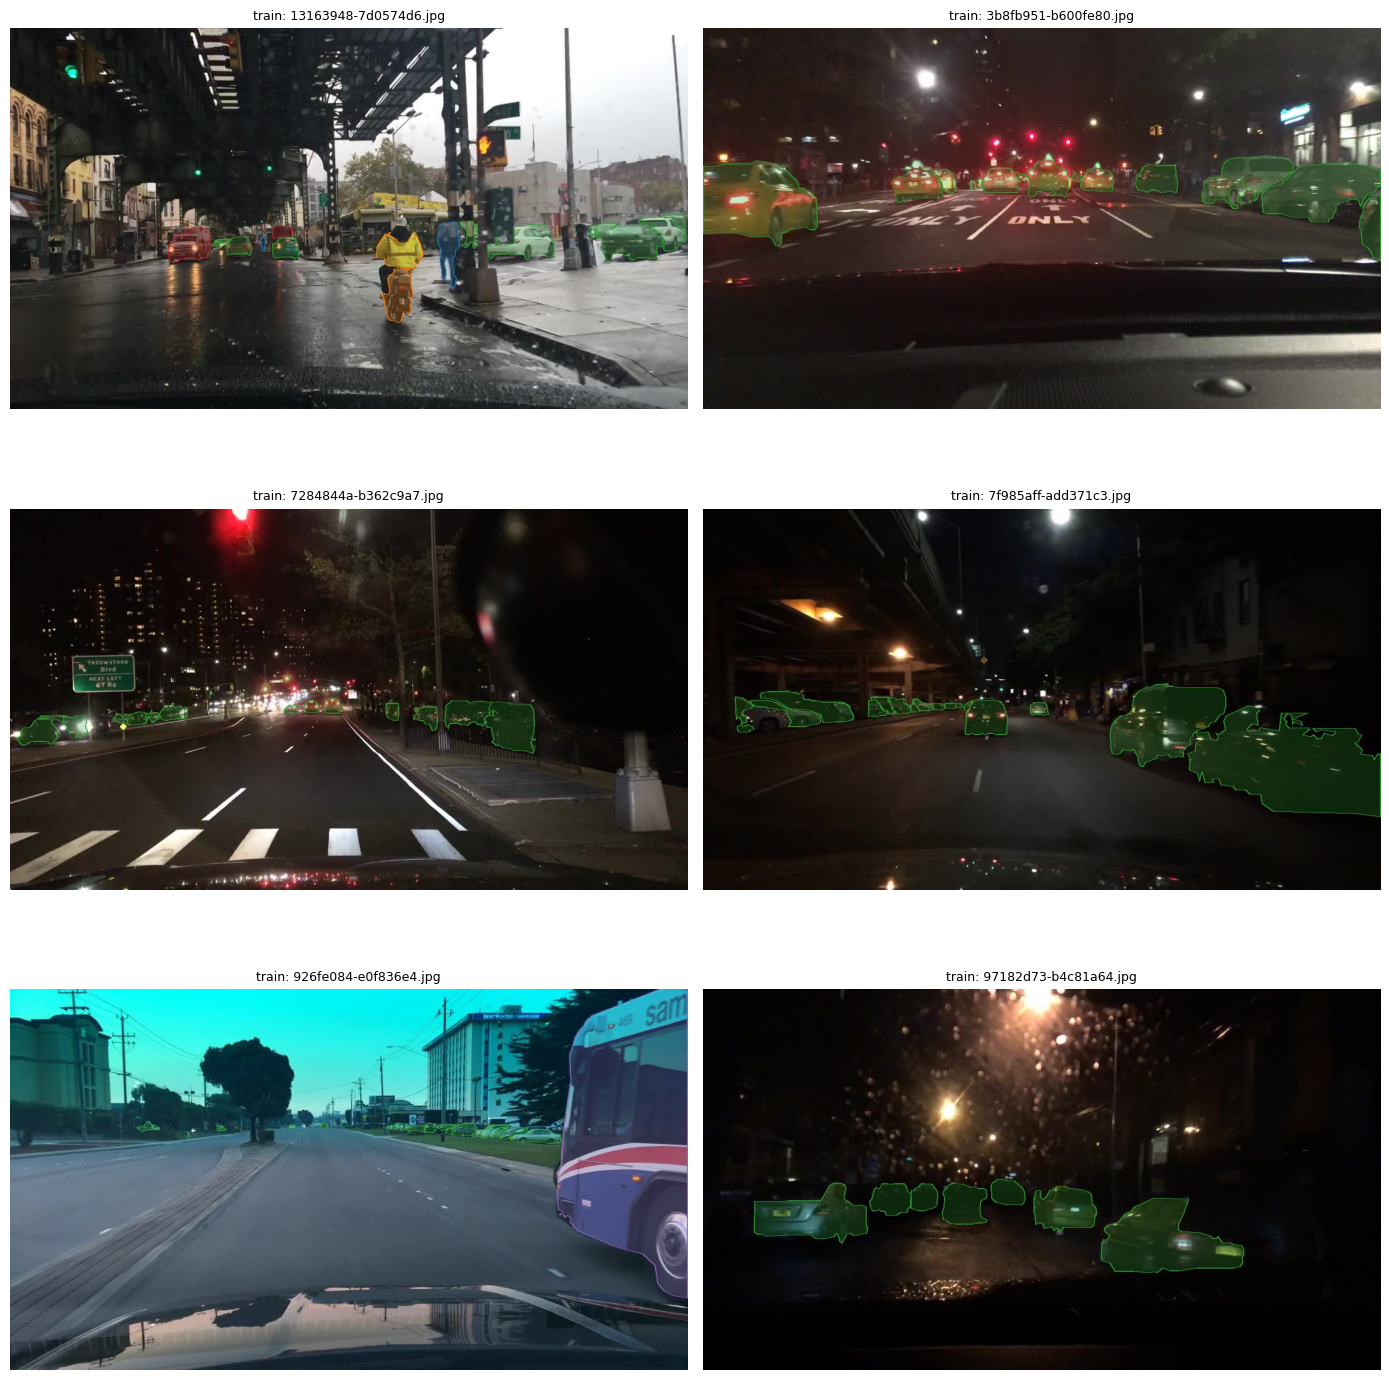


--- VAL ---
Images: 100
Labels: 100
Images without labels: 0
Labels without images: 0
Invalid label lines: 0
Polygon counts by class ID: {0: 163, 1: 8, 2: 1137, 3: 43, 4: 14, 6: 4, 7: 13}
Preview images: 6


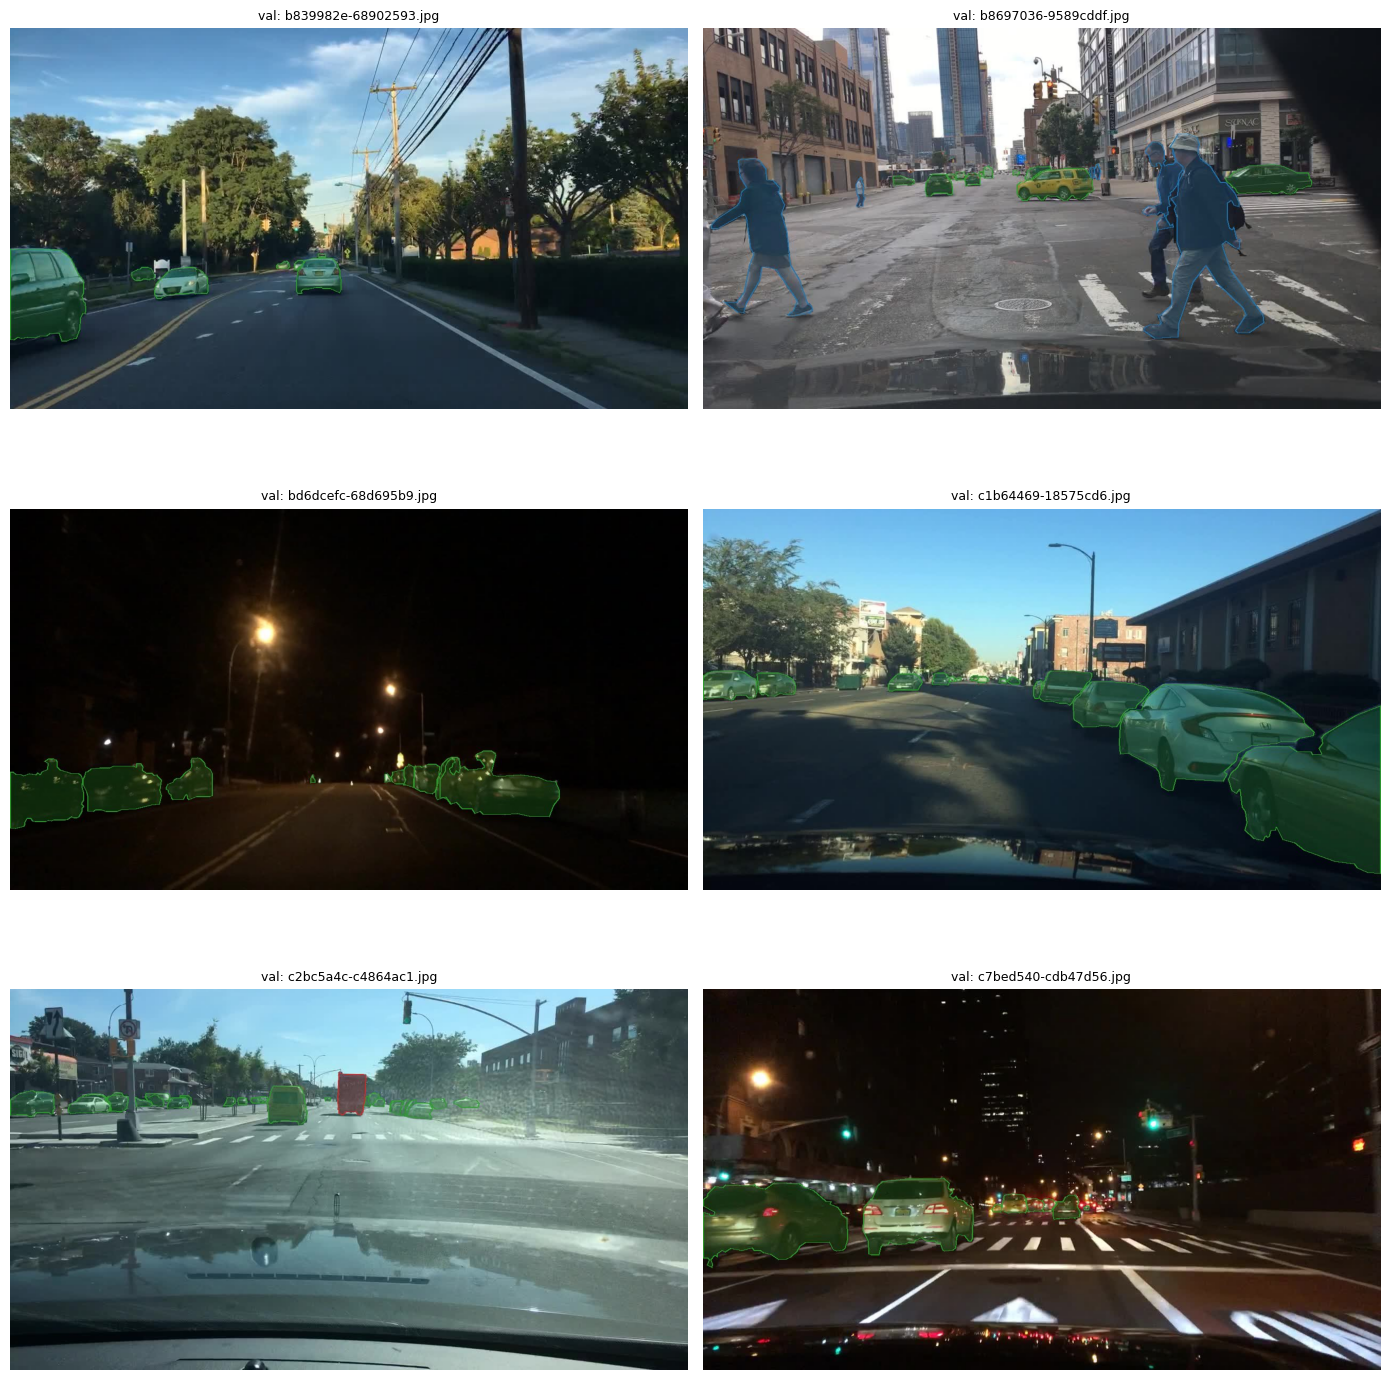


Audit completed. No files were modified.


In [39]:

from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("/kaggle/working/bdd100k_pseudo_project")

print("===== DATASET AUDIT =====")

for split in ["train", "val"]:
    image_dir = ROOT / "images" / split
    label_dir = ROOT / "labels" / split
    preview_dir = ROOT / "previews" / split

    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    counts = Counter()
    invalid_lines = 0

    for label_path in labels:
        for line in label_path.read_text(
            encoding="utf-8"
        ).splitlines():
            parts = line.split()

            try:
                if len(parts) < 7:
                    raise ValueError("Too few polygon coordinates")

                class_id = int(parts[0])
                coords = [float(v) for v in parts[1:]]

                if class_id < 0 or class_id > 7:
                    raise ValueError("Class ID outside range")

                if len(coords) % 2 != 0:
                    raise ValueError("Odd coordinate count")

                if not all(0.0 <= v <= 1.0 for v in coords):
                    raise ValueError("Coordinate outside [0, 1]")

                counts[class_id] += 1

            except Exception:
                invalid_lines += 1

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(image_stems - label_stems))
    print("Labels without images:", len(label_stems - image_stems))
    print("Invalid label lines:", invalid_lines)
    print("Polygon counts by class ID:", dict(sorted(counts.items())))

    previews = sorted(preview_dir.glob("*.jpg"))
    print("Preview images:", len(previews))

    if previews:
        cols = 2
        rows = (len(previews) + cols - 1) // cols

        fig, axes = plt.subplots(
            rows, cols,
            figsize=(14, 5 * rows)
        )
        axes = __import__("numpy").atleast_1d(axes).reshape(-1)

        for ax, path in zip(axes, previews):
            with Image.open(path) as image:
                ax.imshow(image.convert("RGB"))

            ax.set_title(f"{split}: {path.name}", fontsize=9)
            ax.axis("off")

        for ax in axes[len(previews):]:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

print("\nAudit completed. No files were modified.")


In [40]:
# ============================================================
# TRAIN YOLO11x-seg ON 600 SAM-PSEUDO-LABELED BDD100K IMAGES
# ============================================================

from pathlib import Path
import yaml
import torch
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Kiem tra moi truong
# ------------------------------------------------------------

print("===== ENVIRONMENT CHECK =====")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA khong kha dung. Hay bat GPU trong Kaggle Settings."
    )

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3,
        2
    ),
    "GB"
)

# ------------------------------------------------------------
# 2. Kiem tra dataset va data.yaml
# ------------------------------------------------------------

DATA_ROOT = Path(
    "/kaggle/working/bdd100k_pseudo_project"
)

DATA_YAML = DATA_ROOT / "data.yaml"

assert DATA_YAML.exists(), (
    f"Khong tim thay file: {DATA_YAML}"
)

assert (DATA_ROOT / "images/train").is_dir()
assert (DATA_ROOT / "images/val").is_dir()
assert (DATA_ROOT / "labels/train").is_dir()
assert (DATA_ROOT / "labels/val").is_dir()

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

print("\n===== DATASET CONFIGURATION =====")
print("Dataset YAML:", DATA_YAML)
print("Train images:", len(list(
    (DATA_ROOT / "images/train").glob("*")
)))
print("Validation images:", len(list(
    (DATA_ROOT / "images/val").glob("*")
)))
print("Class names:", data_config.get("names"))

print("\nDataset configuration:")
print(yaml.safe_dump(
    data_config,
    allow_unicode=True,
    sort_keys=False
))

# ------------------------------------------------------------
# 3. Nap checkpoint pretrained ban dau
# ------------------------------------------------------------

print("\n===== LOADING PRETRAINED YOLO11x-seg =====")
print("Checkpoint: yolo11x-seg.pt")

model = YOLO("yolo11x-seg.pt")

# ------------------------------------------------------------
# 4. Bat dau training
# ------------------------------------------------------------

print("\n===== STARTING TRAINING =====")

train_results = model.train(
    data=str(DATA_YAML),

    # Training configuration
    epochs=10,
    imgsz=640,
    batch=1,

    # Use the first Kaggle GPU
    device=0,
    workers=2,

    # Save this experiment separately
    project="/kaggle/working/runs",
    name="yolo11x_seg_600_pseudo_v1",

    # Training options
    pretrained=True,
    optimizer="auto",
    patience=10,
    seed=2026,
    amp=True,
    cache=False,
    close_mosaic=2,

    # Evaluation and outputs
    val=True,
    plots=True,
    save=True,
    verbose=True
)

# ------------------------------------------------------------
# 5. Hien thi duong dan checkpoint
# ------------------------------------------------------------

print("\n===== TRAINING FINISHED =====")

run_dir = Path(model.trainer.save_dir)
best_checkpoint = run_dir / "weights" / "best.pt"
last_checkpoint = run_dir / "weights" / "last.pt"

print("Run directory:", run_dir)
print("Best checkpoint:", best_checkpoint)
print("Best checkpoint exists:", best_checkpoint.exists())
print("Last checkpoint:", last_checkpoint)
print("Last checkpoint exists:", last_checkpoint.exists())

===== ENVIRONMENT CHECK =====
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

===== DATASET CONFIGURATION =====
Dataset YAML: /kaggle/working/bdd100k_pseudo_project/data.yaml
Train images: 500
Validation images: 100
Class names: {0: 'person', 1: 'rider', 2: 'car', 3: 'truck', 4: 'bus', 5: 'train', 6: 'motorcycle', 7: 'bicycle'}

Dataset configuration:
path: /kaggle/working/bdd100k_pseudo_project
train: images/train
val: images/val
names:
  0: person
  1: rider
  2: car
  3: truck
  4: bus
  5: train
  6: motorcycle
  7: bicycle


===== LOADING PRETRAINED YOLO11x-seg =====
Checkpoint: yolo11x-seg.pt

===== STARTING TRAINING =====
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False

So anh tim thay: 20000
So anh se kiem tra: 8
d2864b07-ce2cb4ec.jpg
f1f09186-5e5e6f75.jpg
e4bfd936-b7540d8f.jpg
e6e7a923-5110b3b9.jpg
cfd44479-d67c778c.jpg
e330a5f8-e470c444.jpg
fb96a9a2-d53262ea.jpg
f107ec61-9055fcb0.jpg


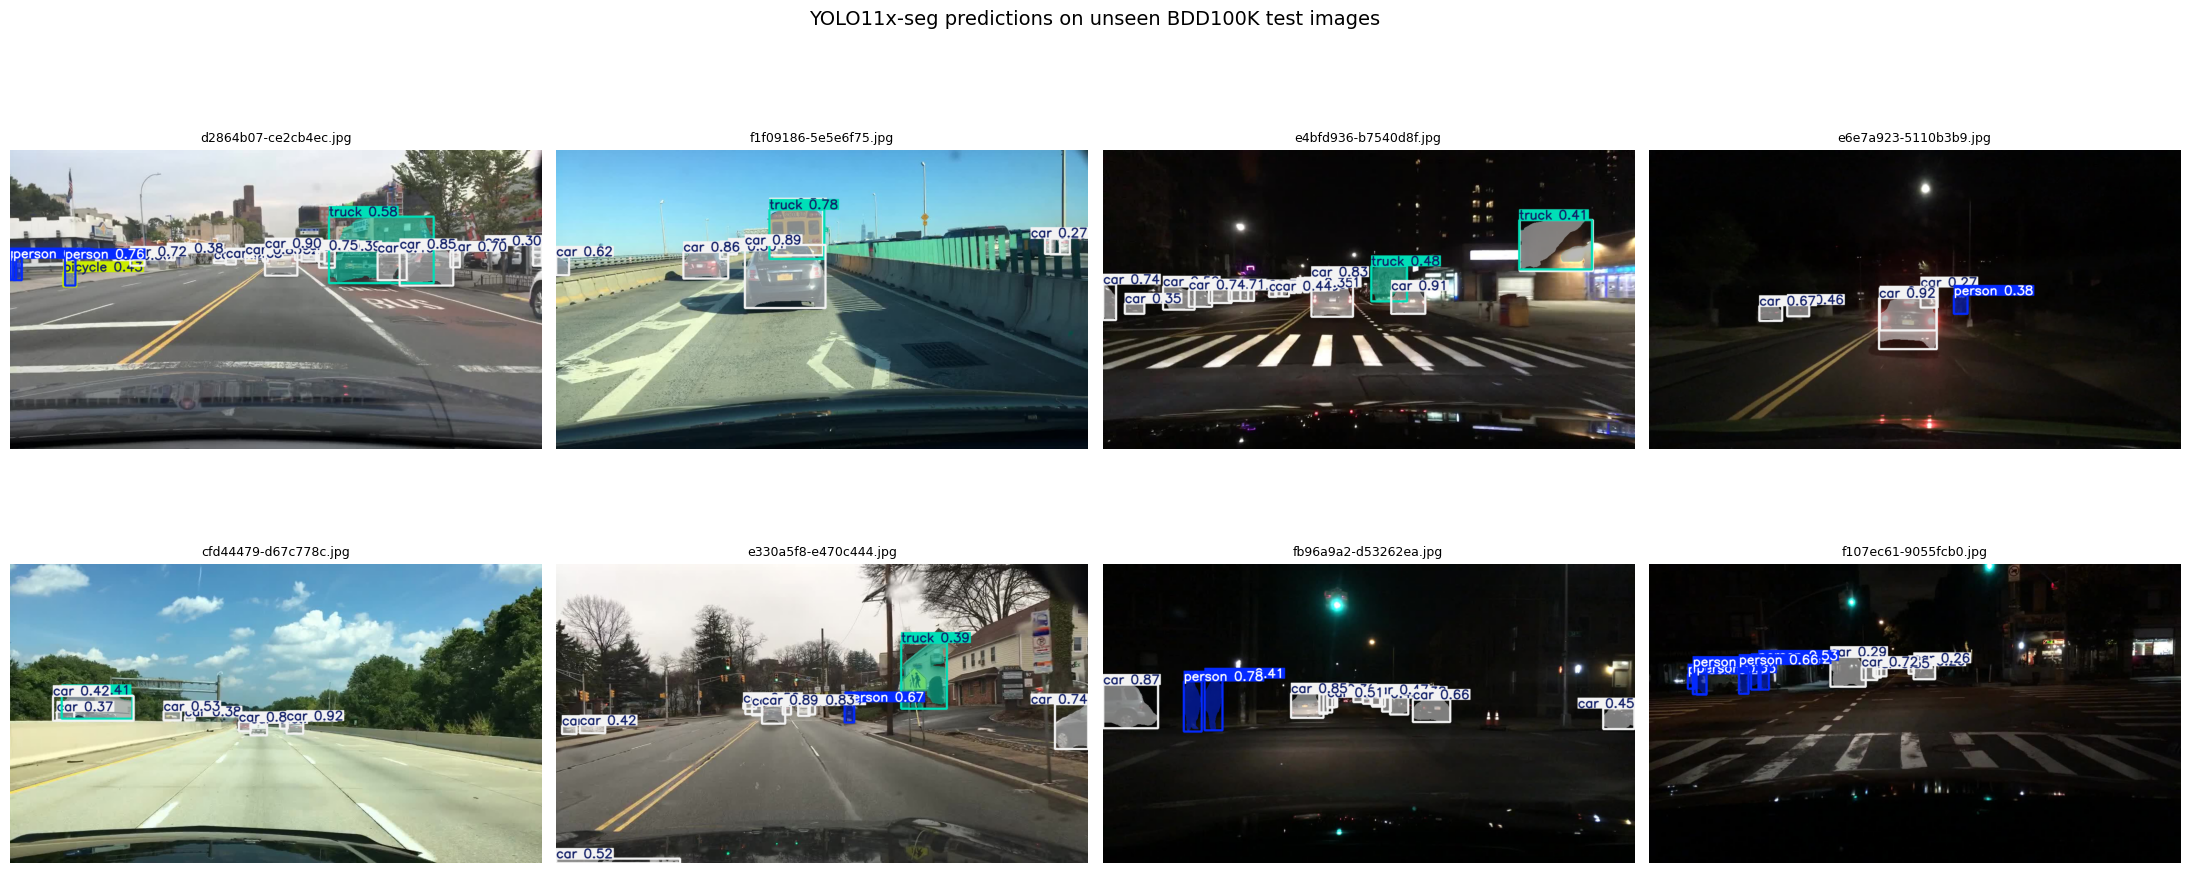


===== PREDICTION SUMMARY =====

d2864b07-ce2cb4ec.jpg
So doi tuong du doan: 22
Theo lop: {'car': 17, 'person': 3, 'truck': 1, 'bicycle': 1}

f1f09186-5e5e6f75.jpg
So doi tuong du doan: 9
Theo lop: {'car': 8, 'truck': 1}

e4bfd936-b7540d8f.jpg
So doi tuong du doan: 18
Theo lop: {'car': 16, 'truck': 2}

e6e7a923-5110b3b9.jpg
So doi tuong du doan: 6
Theo lop: {'car': 5, 'person': 1}

cfd44479-d67c778c.jpg
So doi tuong du doan: 9
Theo lop: {'car': 8, 'truck': 1}

e330a5f8-e470c444.jpg
So doi tuong du doan: 13
Theo lop: {'car': 11, 'person': 1, 'truck': 1}

fb96a9a2-d53262ea.jpg
So doi tuong du doan: 16
Theo lop: {'car': 14, 'person': 2}

f107ec61-9055fcb0.jpg
So doi tuong du doan: 12
Theo lop: {'car': 6, 'person': 6}


In [41]:
from pathlib import Path
from collections import Counter
import random

import torch
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

# --------------------------------------------------
# 1. Duong dan
# --------------------------------------------------

INPUT_ROOT = Path(
    "/kaggle/input/datasets/solesensei/solesensei_bdd100k"
)

BEST_MODEL = Path(
    "/kaggle/working/runs/"
    "yolo11x_seg_600_pseudo_v1/weights/best.pt"
)

assert BEST_MODEL.exists(), (
    f"Khong tim thay checkpoint: {BEST_MODEL}"
)

# --------------------------------------------------
# 2. Tim thu muc anh test
# --------------------------------------------------

possible_roots = [
    INPUT_ROOT / "bdd100k/bdd100k/images/100k",
    INPUT_ROOT / "bdd100k/images/100k",
]

image_root = next(
    (p for p in possible_roots if p.is_dir()),
    None
)

if image_root is None:
    raise FileNotFoundError(
        "Khong tim thay thu muc images/100k. "
        "Hay kiem tra lai cau truc dataset trong Kaggle."
    )

# Uu tien thu muc test chinh thuc.
test_dir = image_root / "test"

# Neu khong co thu muc test truc tiep, tim cac thu muc
# test co the nam trong cau truc dataset.
if not test_dir.is_dir():
    alternatives = [
        p for p in image_root.iterdir()
        if p.is_dir() and p.name.lower() in {
            "test", "testa", "testb"
        }
    ]

    if not alternatives:
        raise FileNotFoundError(
            f"Khong tim thay thu muc test trong {image_root}. "
            f"Cac thu muc hien co: "
            f"{[p.name for p in image_root.iterdir() if p.is_dir()]}"
        )

    test_dirs = alternatives
else:
    test_dirs = [test_dir]

# --------------------------------------------------
# 3. Lay ngau nhien toi da 8 anh
# --------------------------------------------------

image_files = []

for folder in test_dirs:
    image_files.extend(folder.rglob("*.jpg"))
    image_files.extend(folder.rglob("*.jpeg"))
    image_files.extend(folder.rglob("*.png"))

image_files = sorted(set(image_files))

if not image_files:
    raise RuntimeError(
        "Khong tim thay anh trong thu muc test."
    )

random.seed(2026)
sample_images = random.sample(
    image_files,
    k=min(8, len(image_files))
)

print("So anh tim thay:", len(image_files))
print("So anh se kiem tra:", len(sample_images))
for p in sample_images:
    print(p.name)

# --------------------------------------------------
# 4. Load best checkpoint va predict
# --------------------------------------------------

assert torch.cuda.is_available(), "Kaggle GPU chua bat."

model = YOLO(str(BEST_MODEL))

results = model.predict(
    source=[str(p) for p in sample_images],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=0,
    retina_masks=True,
    verbose=False
)

# --------------------------------------------------
# 5. Hien thi mask va bounding box
# --------------------------------------------------

class_names = model.names

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

for i, result in enumerate(results):
    # result.plot() tra ve anh BGR; matplotlib can RGB.
    plotted = result.plot()
    plotted = plotted[:, :, ::-1]

    axes[i].imshow(plotted)
    axes[i].set_title(sample_images[i].name, fontsize=9)
    axes[i].axis("off")

for i in range(len(results), len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "YOLO11x-seg predictions on unseen BDD100K test images",
    fontsize=14
)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Thong ke so du doan tren tung anh
# --------------------------------------------------

print("\n===== PREDICTION SUMMARY =====")

for path, result in zip(sample_images, results):
    class_counts = Counter()

    if result.boxes is not None and len(result.boxes) > 0:
        class_ids = result.boxes.cls.cpu().tolist()

        for class_id in class_ids:
            class_name = class_names[int(class_id)]
            class_counts[class_name] += 1

    print(f"\n{path.name}")
    print("So doi tuong du doan:", sum(class_counts.values()))
    print("Theo lop:", dict(class_counts))

HTML report created successfully.
File: /kaggle/working/yolo11x_predictions_report.html
File size: 1.12 MB
Images included: 8



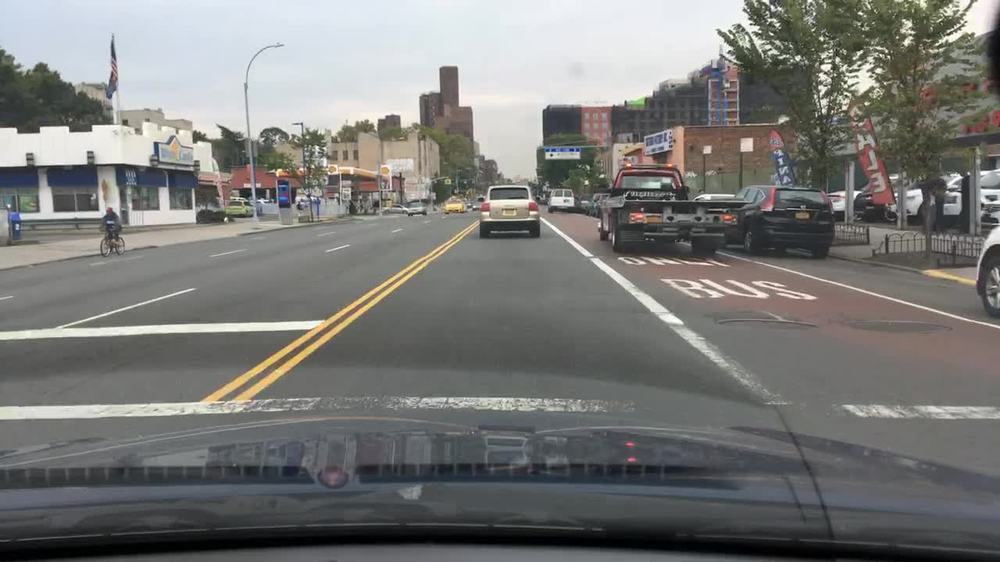
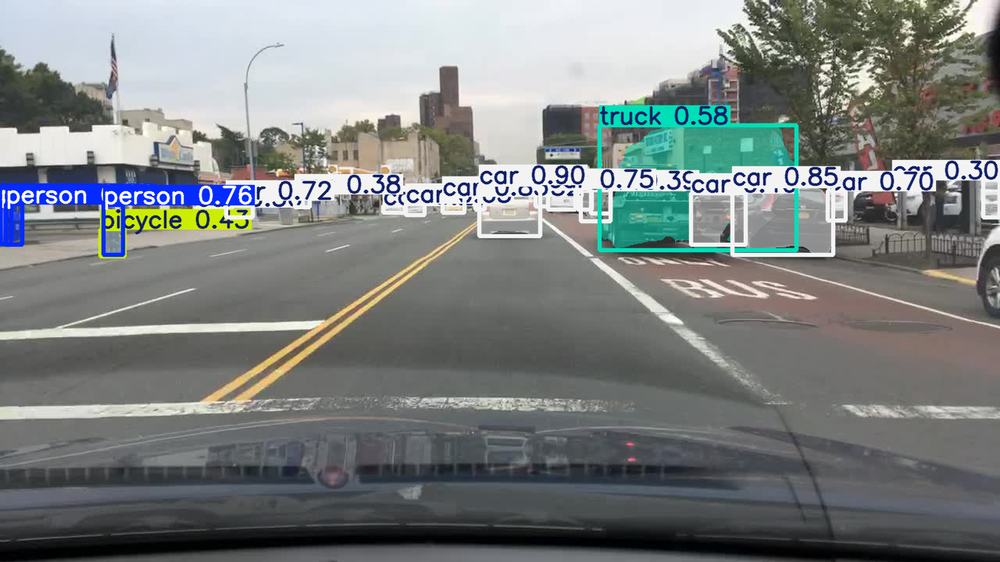
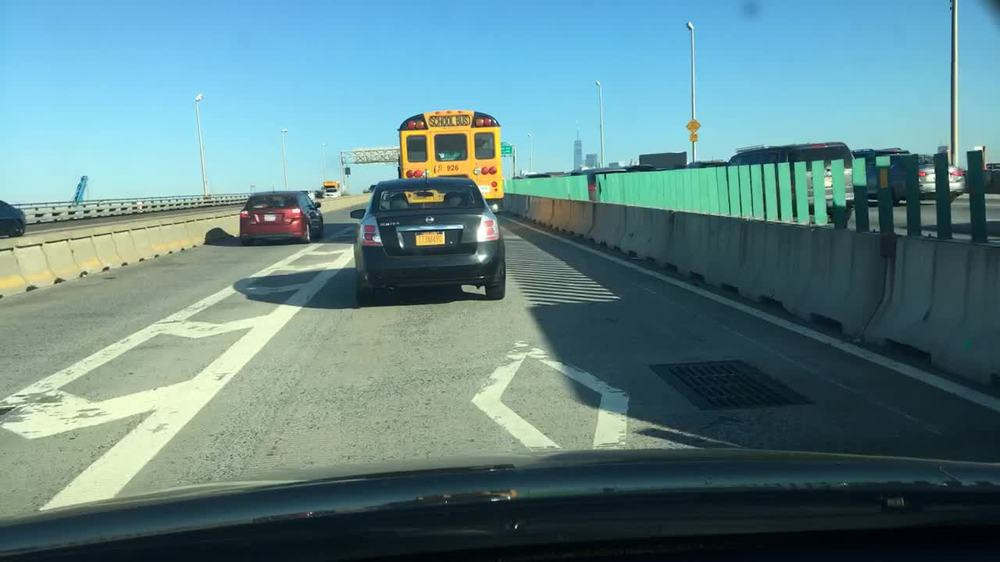
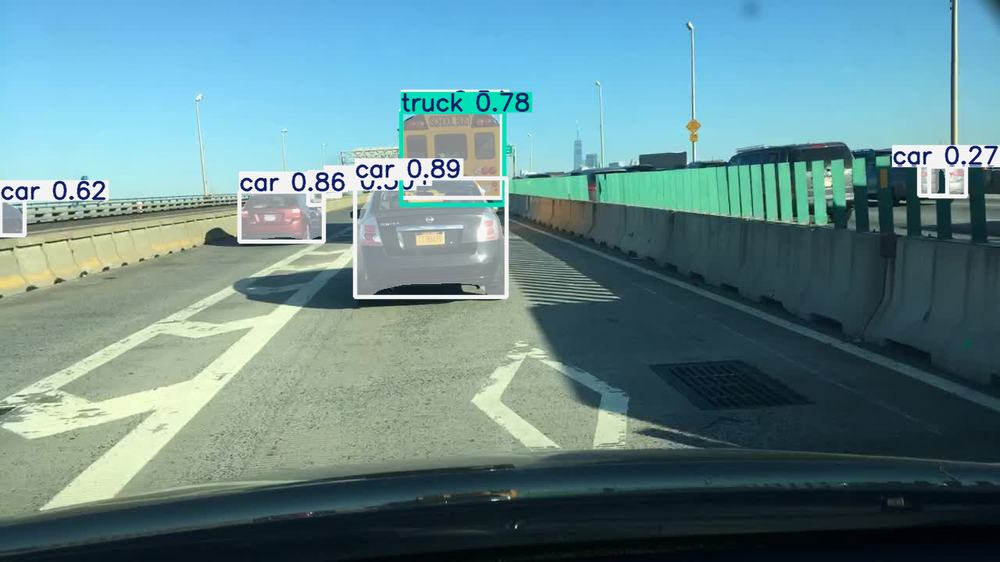
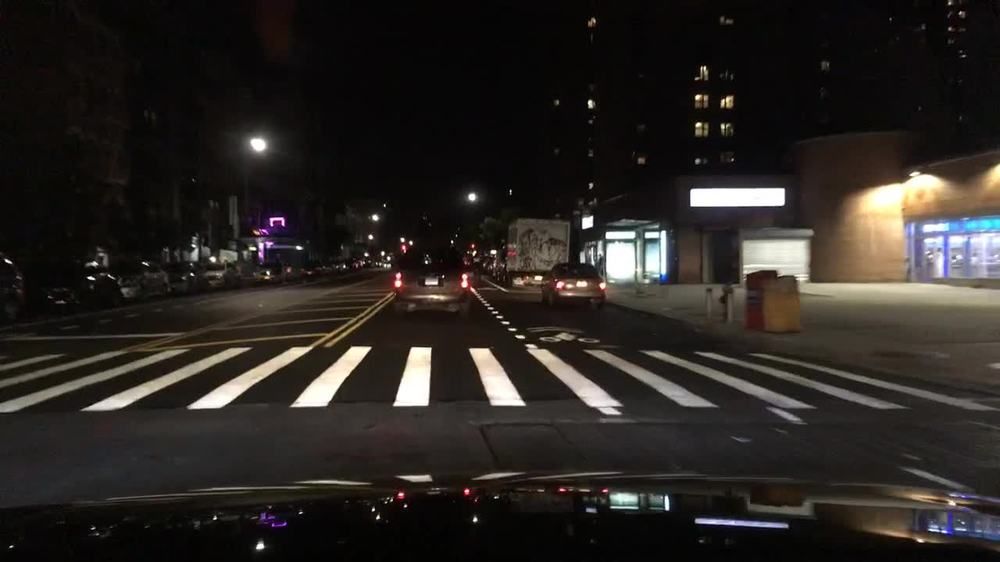
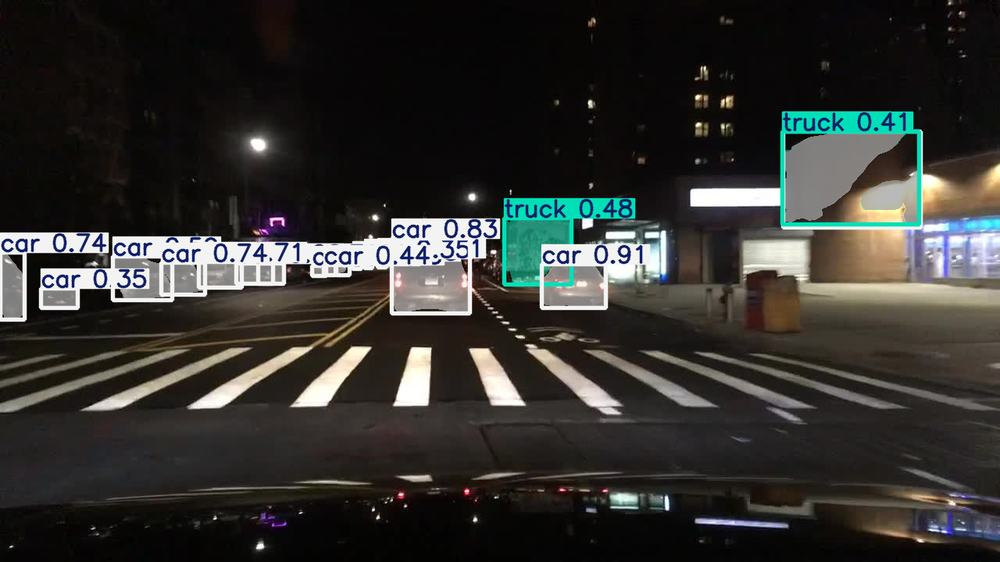
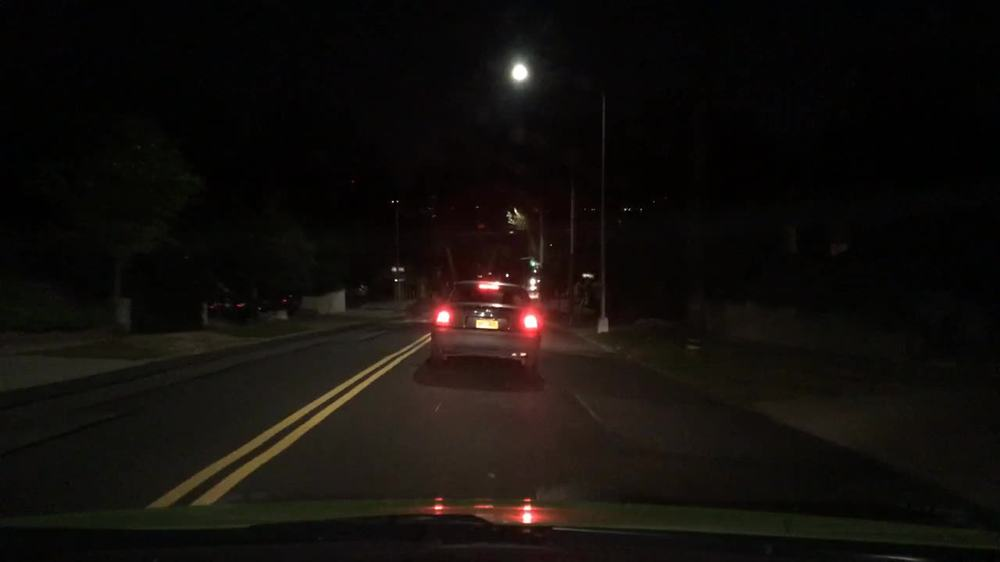
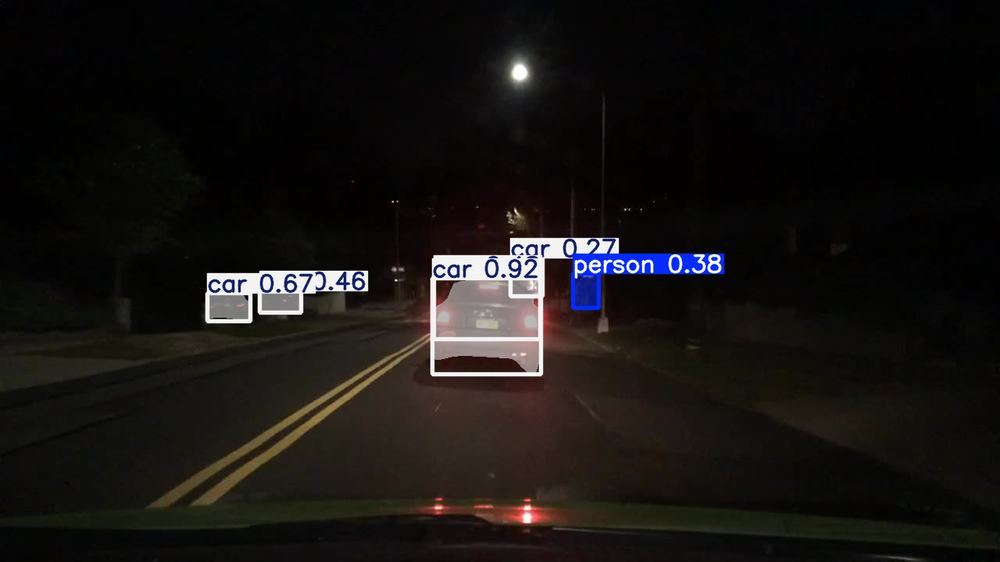
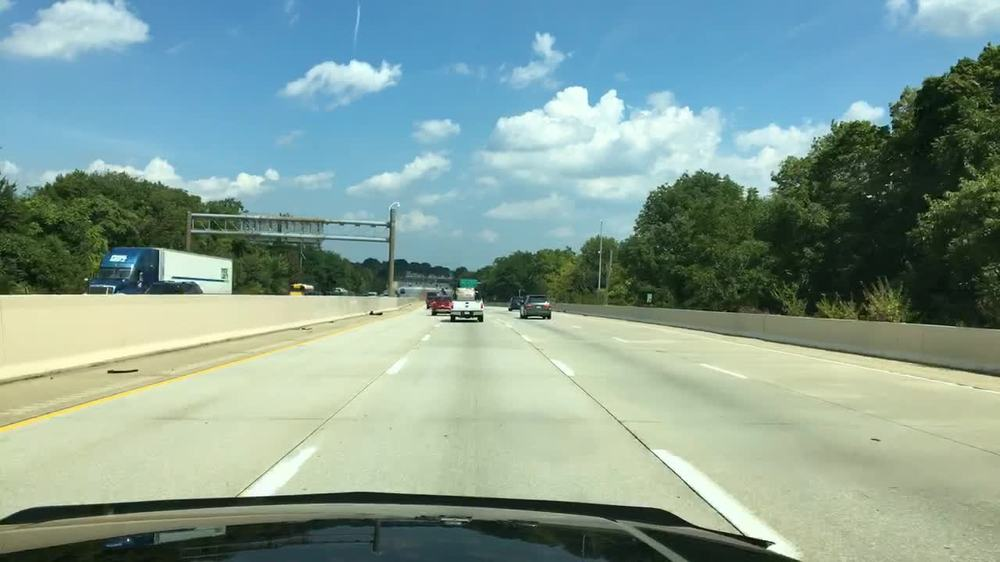
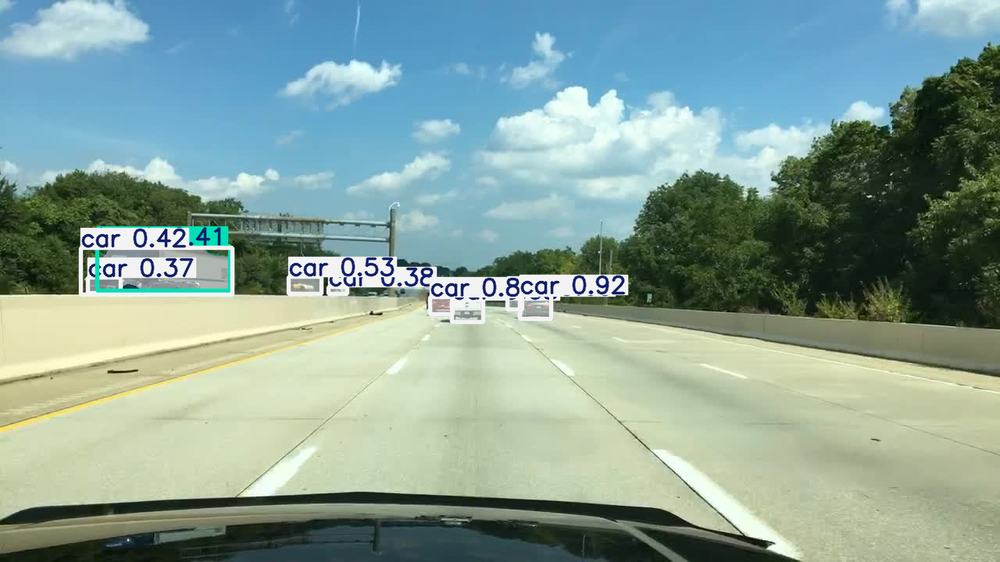
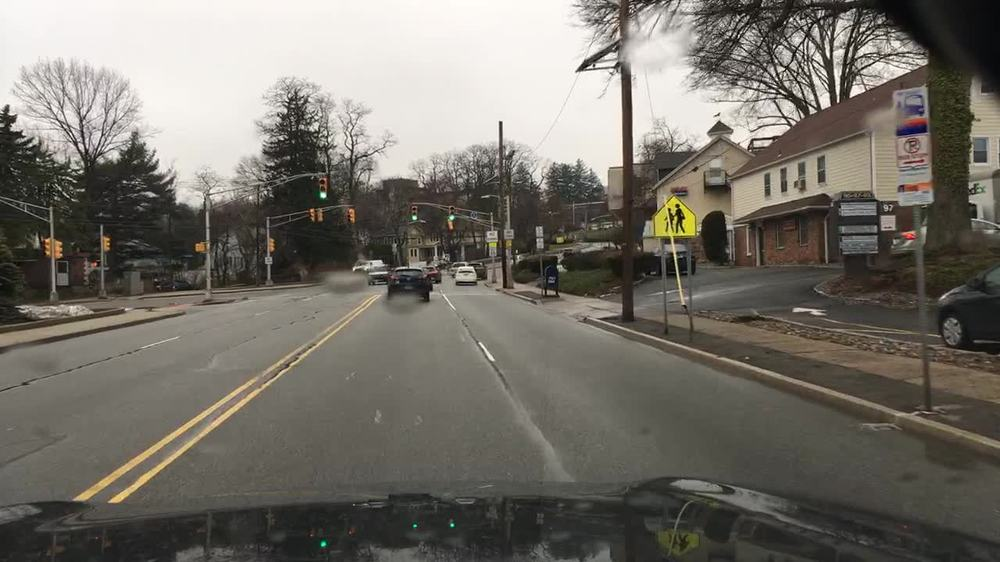
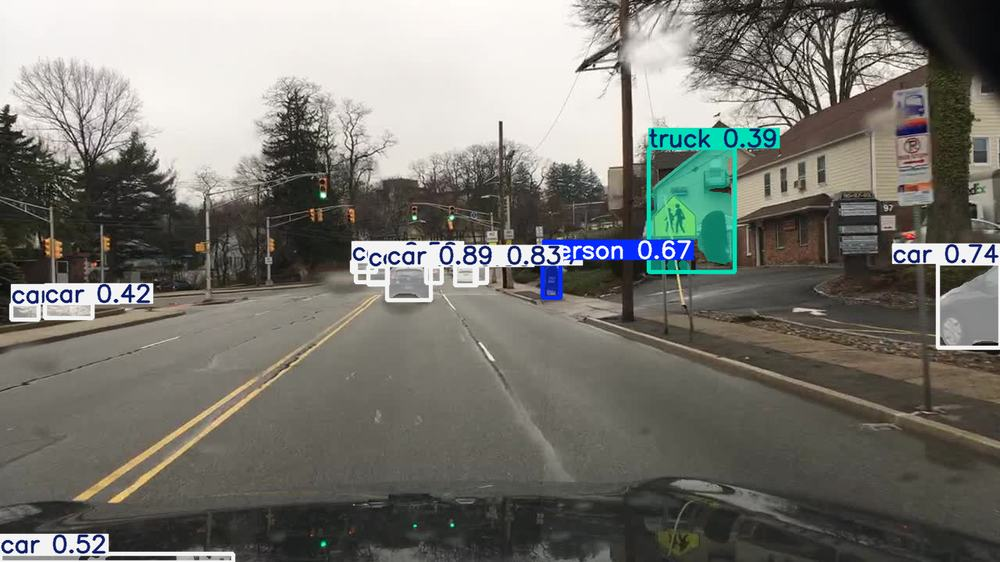
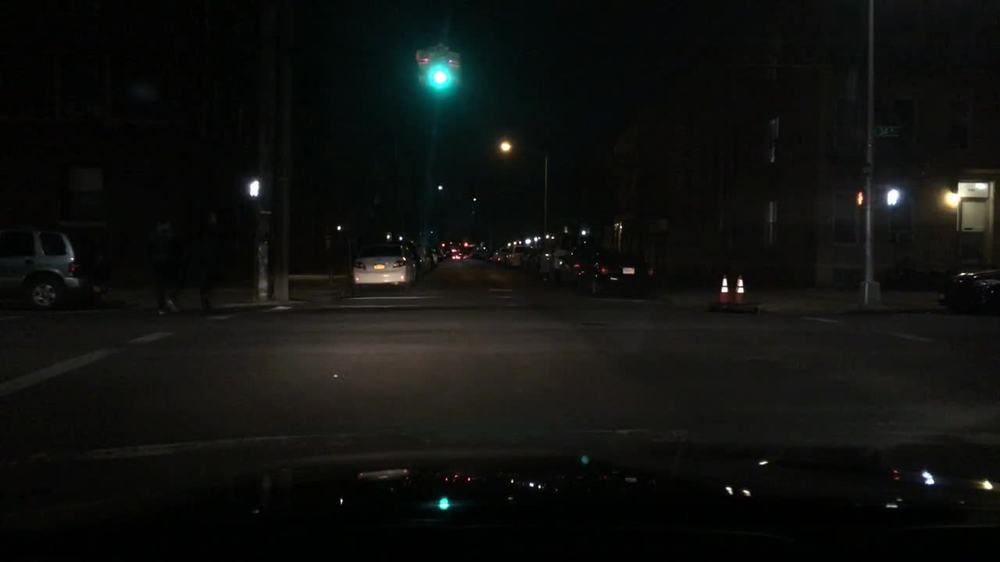
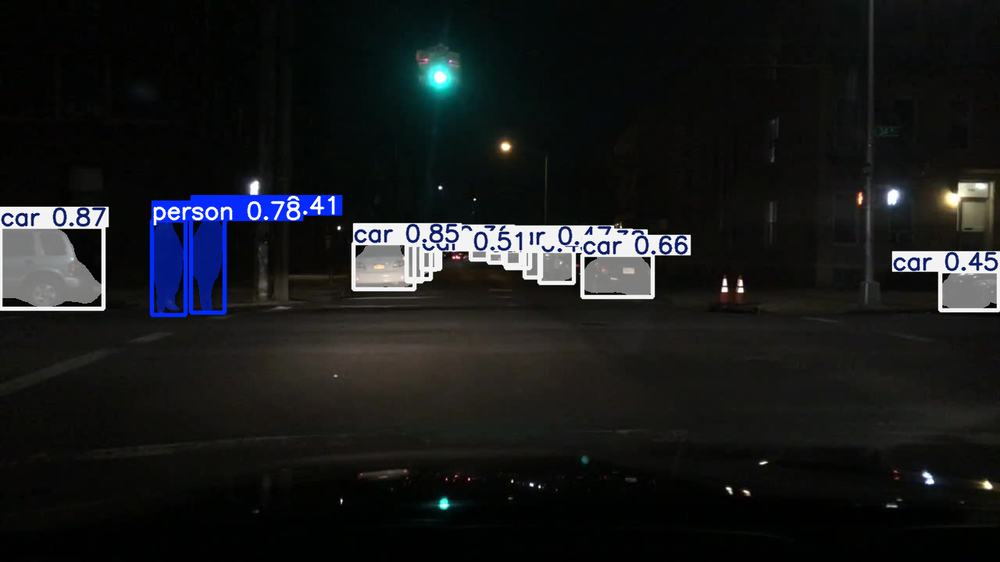
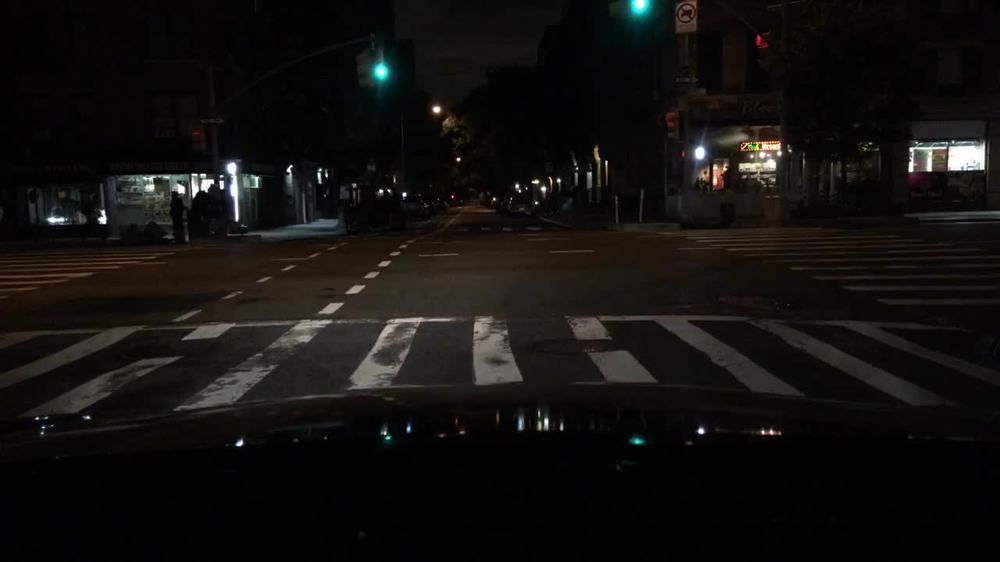
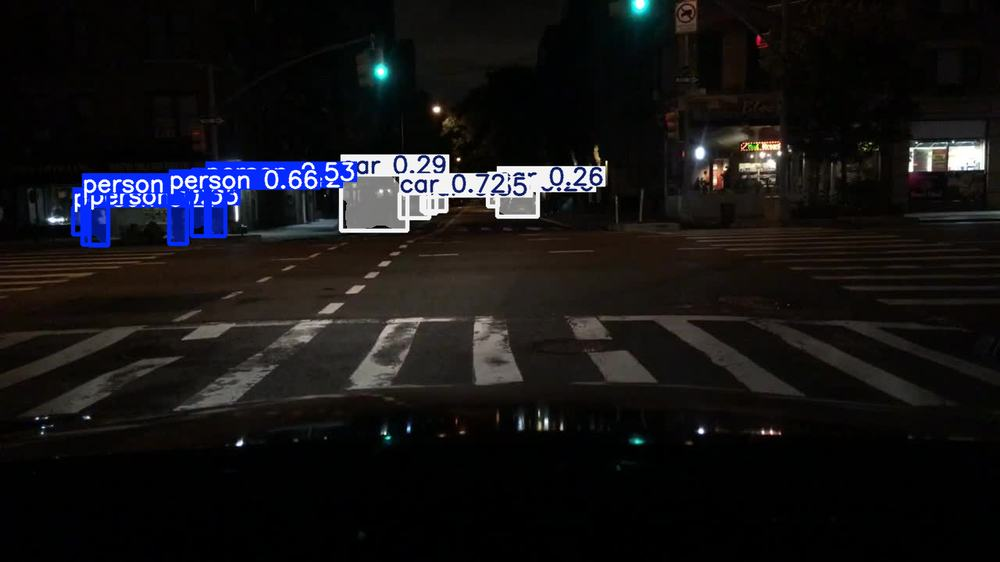

In [42]:

from pathlib import Path
from collections import Counter
from io import BytesIO
from base64 import b64encode
import html
import numpy as np

from PIL import Image
from IPython.display import display, HTML

# ============================================================
# 1. Kiem tra ket qua du doan tu cell truoc
# ============================================================

if "sample_images" not in globals() or "results" not in globals():
    raise RuntimeError(
        "Khong tim thay sample_images/results. "
        "Hay chay lai cell predict 8 anh truoc."
    )

if len(sample_images) != len(results):
    raise RuntimeError("So anh va ket qua predict khong khop.")

# ============================================================
# 2. Ham chuyen anh thanh chuoi Base64
#    Anh duoc nhung truc tiep vao HTML
# ============================================================

def image_to_base64(image, max_width=1000, quality=76):
    image = image.convert("RGB")

    # Thu nho anh de HTML khong qua nang
    if image.width > max_width:
        new_height = round(image.height * max_width / image.width)
        image = image.resize(
            (max_width, new_height),
            Image.Resampling.LANCZOS
        )

    buffer = BytesIO()
    image.save(
        buffer,
        format="JPEG",
        quality=quality,
        optimize=True
    )

    encoded = b64encode(buffer.getvalue()).decode("ascii")
    return f"data:image/jpeg;base64,{encoded}"

# ============================================================
# 3. Tao tung muc bao cao
# ============================================================

report_cards = []

total_predictions = 0
all_class_counts = Counter()

for index, (image_path, result) in enumerate(
    zip(sample_images, results), start=1
):
    image_path = Path(image_path)

    # Anh goc
    with Image.open(image_path) as source:
        original_image = source.copy().convert("RGB")

    # Anh ket qua predict: result.plot() tra ve anh theo BGR
    plotted_bgr = result.plot()
    predicted_image = Image.fromarray(
        np.ascontiguousarray(plotted_bgr[:, :, ::-1])
    )

    original_uri = image_to_base64(original_image)
    predicted_uri = image_to_base64(predicted_image)

    # Dem so doi tuong theo lop
    class_counts = Counter()
    details = []

    if result.boxes is not None and len(result.boxes) > 0:
        class_ids = result.boxes.cls.cpu().tolist()
        confidences = result.boxes.conf.cpu().tolist()

        for class_id, confidence in zip(class_ids, confidences):
            class_name = result.names[int(class_id)]
            class_counts[class_name] += 1
            all_class_counts[class_name] += 1

            details.append(
                f"{html.escape(class_name)} "
                f"(confidence={confidence:.2f})"
            )

    total_predictions += sum(class_counts.values())

    if class_counts:
        class_summary = ", ".join(
            f"{html.escape(name)}: {count}"
            for name, count in sorted(class_counts.items())
        )
        detection_details = "<br>".join(details)
    else:
        class_summary = "Khong co doi tuong duoc phat hien"
        detection_details = "Khong co du doan"

    safe_filename = html.escape(image_path.name)

    card = f"""
    <section class="card">
        <h2>Image {index}: {safe_filename}</h2>

        <div class="image-grid">
            <div class="image-panel">
                <h3>Original image</h3>
                <img src="{original_uri}" alt="Original image">
            </div>

            <div class="image-panel">
                <h3>YOLO11x-seg prediction</h3>
                <img src="{predicted_uri}" alt="Predicted masks and boxes">
            </div>
        </div>

        <p><strong>Number of predictions:</strong>
           {sum(class_counts.values())}</p>

        <p><strong>Predictions by class:</strong>
           {class_summary}</p>

        <details>
            <summary>Confidence of individual detections</summary>
            <p>{detection_details}</p>
        </details>
    </section>
    """
    report_cards.append(card)

# ============================================================
# 4. Ghep thanh mot file HTML doc lap
# ============================================================

summary_by_class = ", ".join(
    f"{html.escape(name)}: {count}"
    for name, count in sorted(all_class_counts.items())
)

report_html = f"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>YOLO11x-seg BDD100K Prediction Report</title>
<style>
    body {{
        font-family: Arial, sans-serif;
        margin: 24px auto;
        padding: 0 18px;
        max-width: 1500px;
        color: #222;
        background: #f5f6f8;
        line-height: 1.5;
    }}
    h1 {{ margin-bottom: 8px; }}
    .summary {{
        background: white;
        padding: 16px;
        border-radius: 8px;
        margin: 18px 0;
    }}
    .card {{
        background: white;
        padding: 18px;
        border-radius: 8px;
        margin: 20px 0;
        box-shadow: 0 1px 5px #00000014;
    }}
    .image-grid {{
        display: grid;
        grid-template-columns: repeat(2, minmax(0, 1fr));
        gap: 16px;
    }}
    .image-panel {{ min-width: 0; }}
    .image-panel img {{
        display: block;
        width: 100%;
        height: auto;
        border: 1px solid #ddd;
        border-radius: 4px;
    }}
    h2 {{ font-size: 19px; overflow-wrap: anywhere; }}
    h3 {{ font-size: 15px; }}
    details {{ margin-top: 10px; }}
    @media (max-width: 750px) {{
        .image-grid {{ grid-template-columns: 1fr; }}
    }}
</style>
</head>
<body>
    <h1>YOLO11x-seg Prediction Report</h1>
    <p>BDD100K test images | Confidence threshold: 0.25</p>

    <div class="summary">
        <h2>Overall summary</h2>
        <p><strong>Images inspected:</strong> {len(results)}</p>
        <p><strong>Total detections:</strong> {total_predictions}</p>
        <p><strong>Detections by class:</strong> {summary_by_class}</p>
        <p>
          The prediction overlay shows the model's detections.
          Visual inspection is not a substitute for evaluation
          against ground-truth instance masks.
        </p>
    </div>

    {''.join(report_cards)}
</body>
</html>
"""

# ============================================================
# 5. Luu file vao Kaggle working
# ============================================================

output_path = Path(
    "/kaggle/working/yolo11x_predictions_report.html"
)

output_path.write_text(report_html, encoding="utf-8")

file_size_mb = output_path.stat().st_size / (1024 * 1024)

print("HTML report created successfully.")
print("File:", output_path)
print(f"File size: {file_size_mb:.2f} MB")
print("Images included:", len(results))

# Hien thi bao cao ngay trong Notebook
display(HTML(report_html))



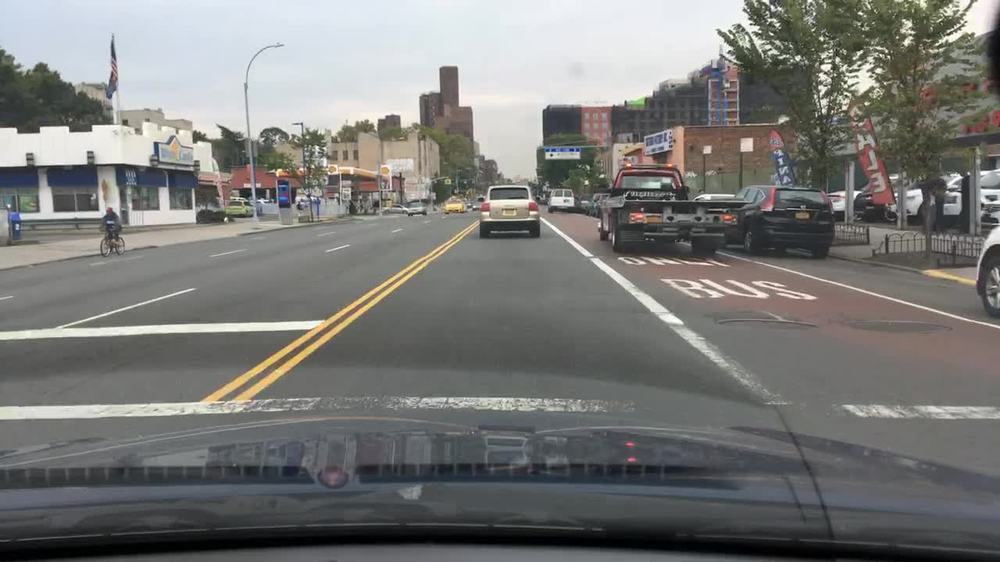
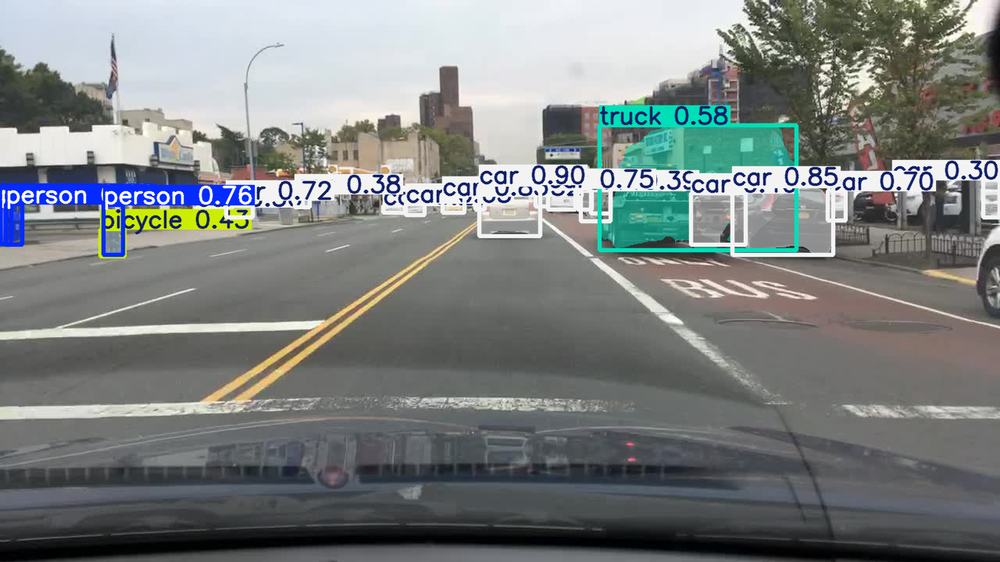
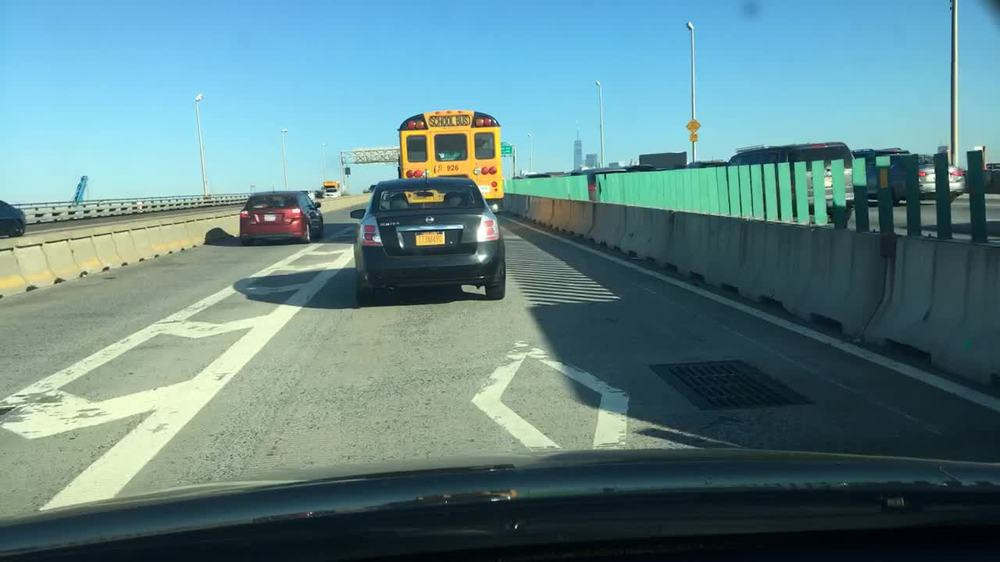
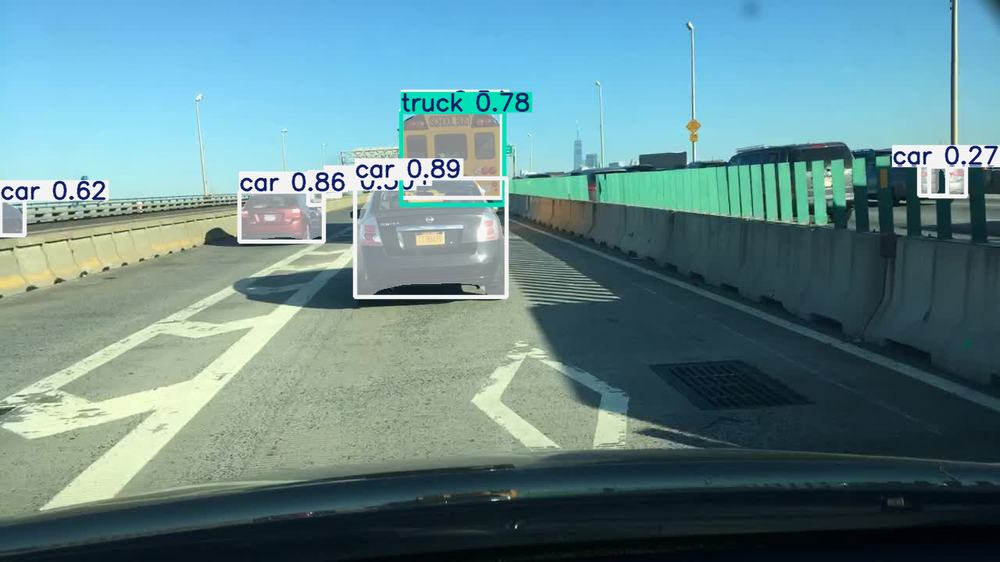
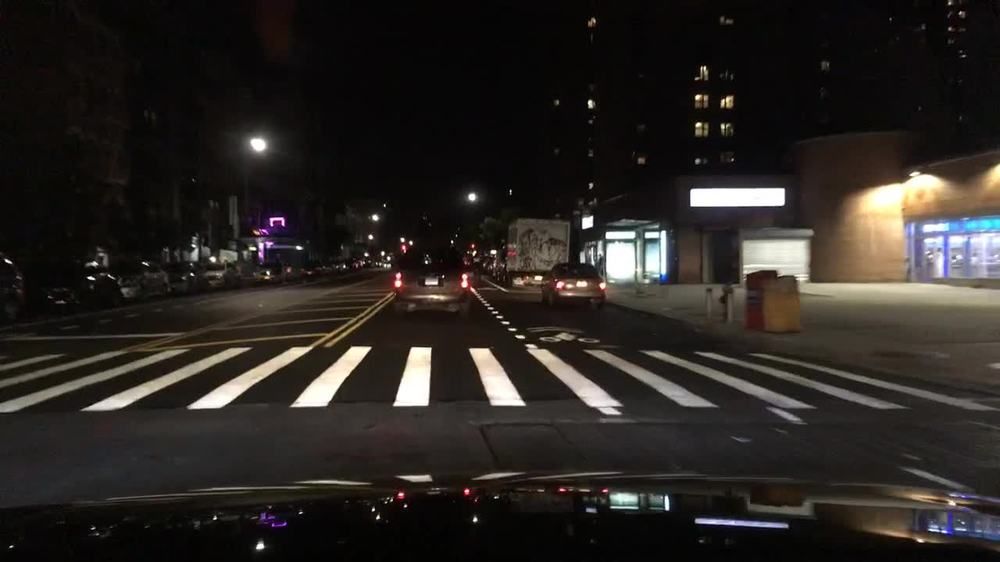
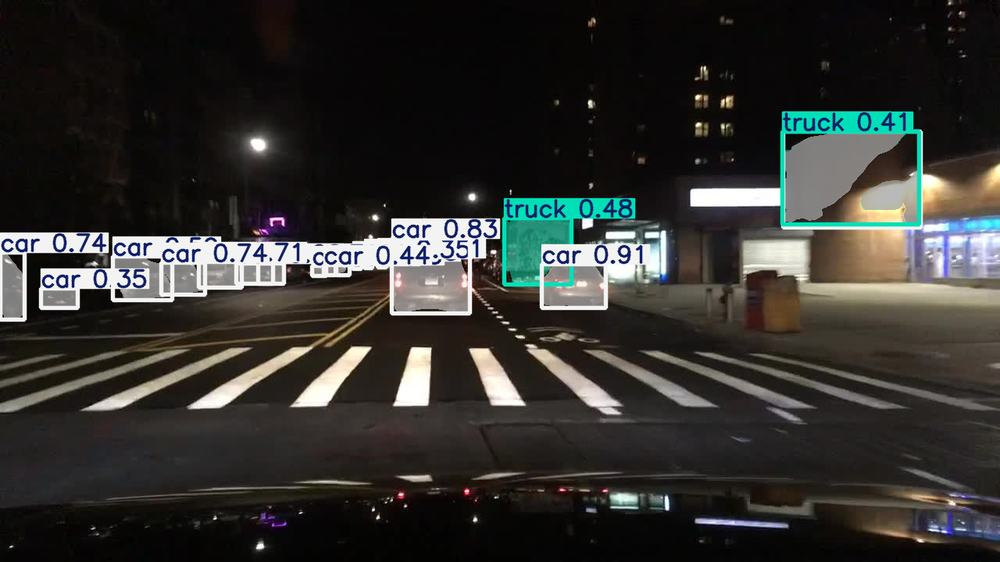
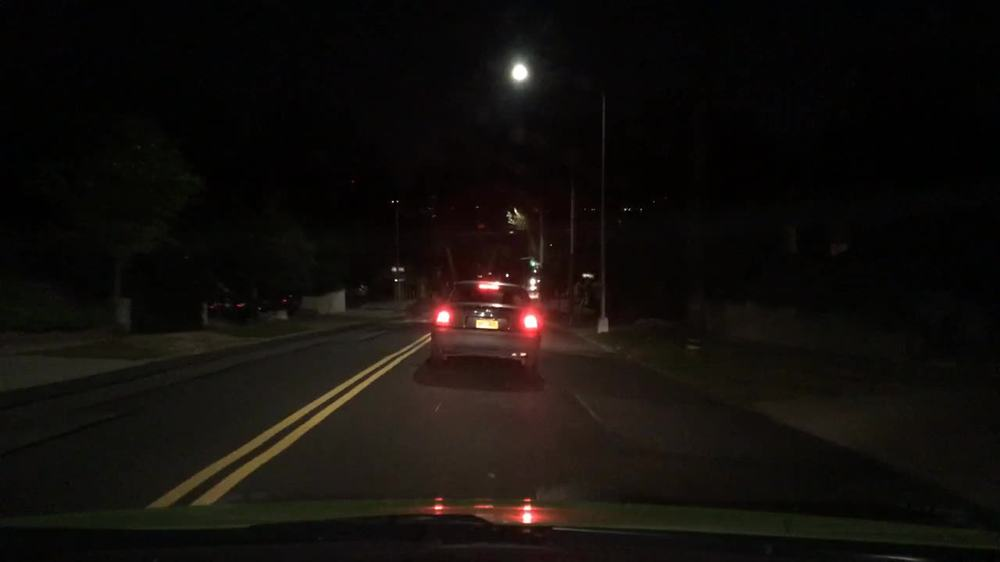
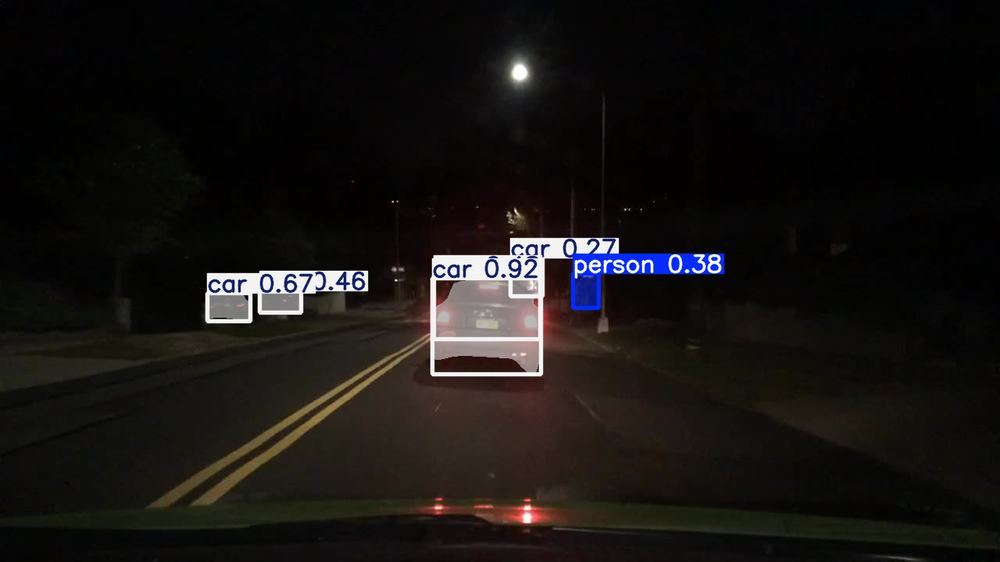
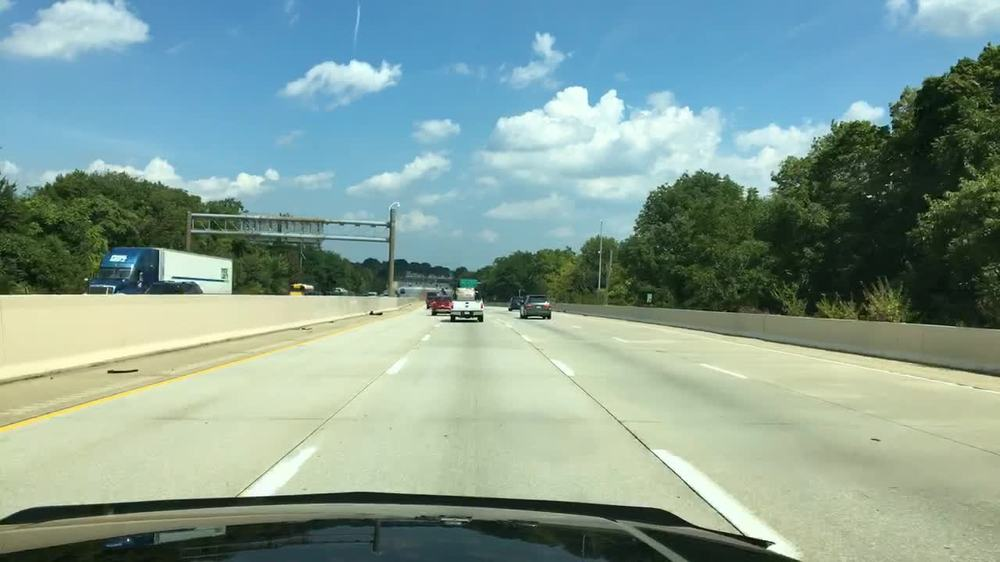
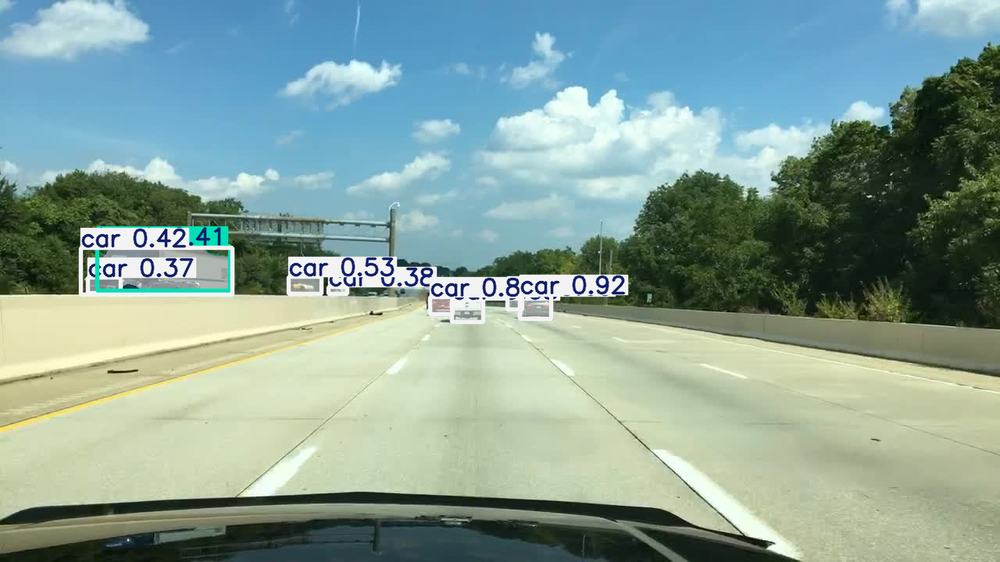
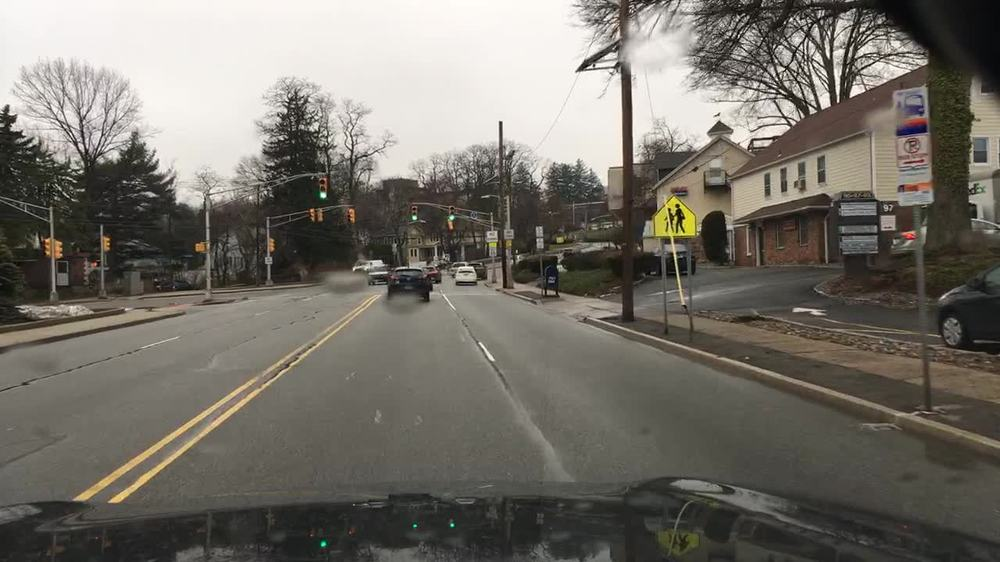
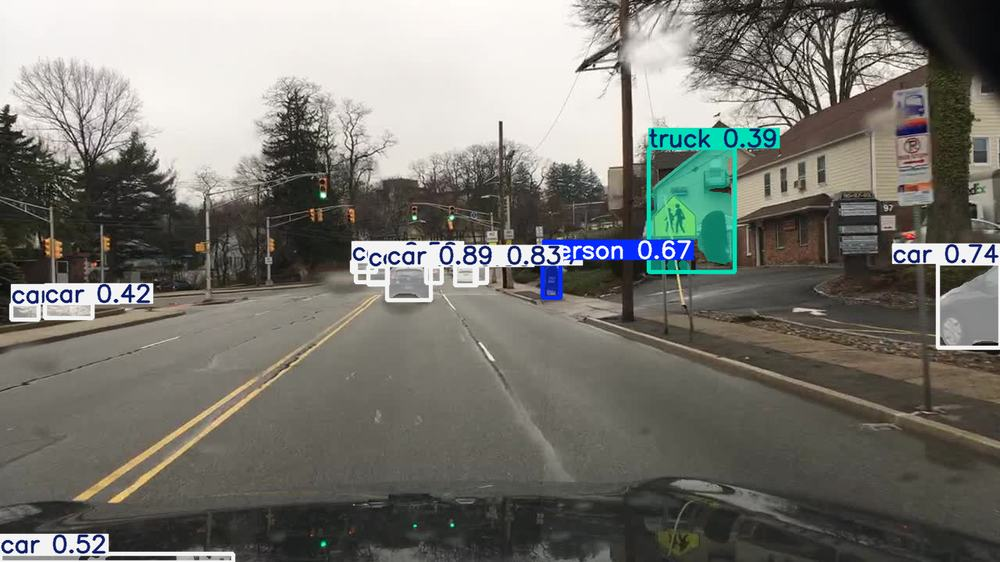
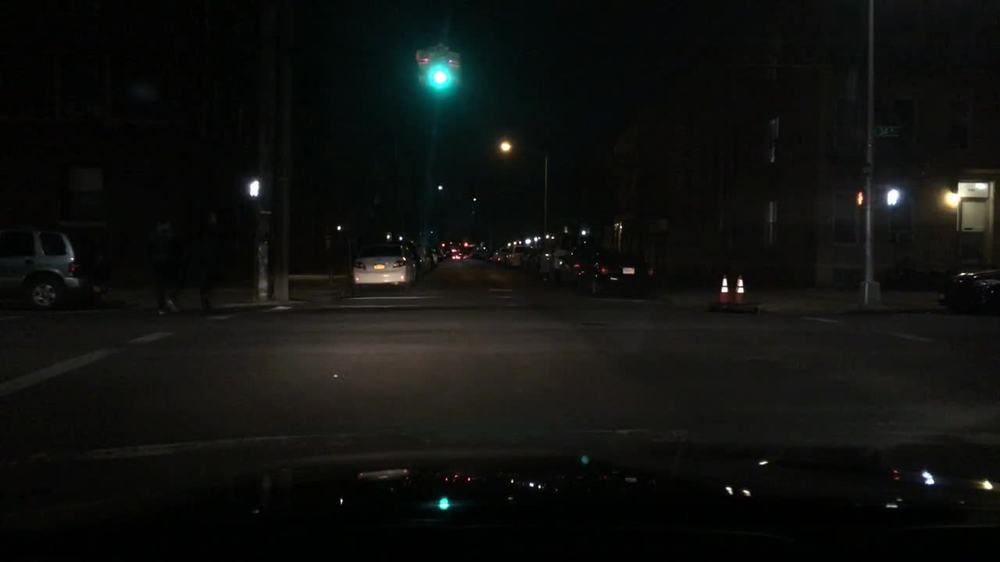
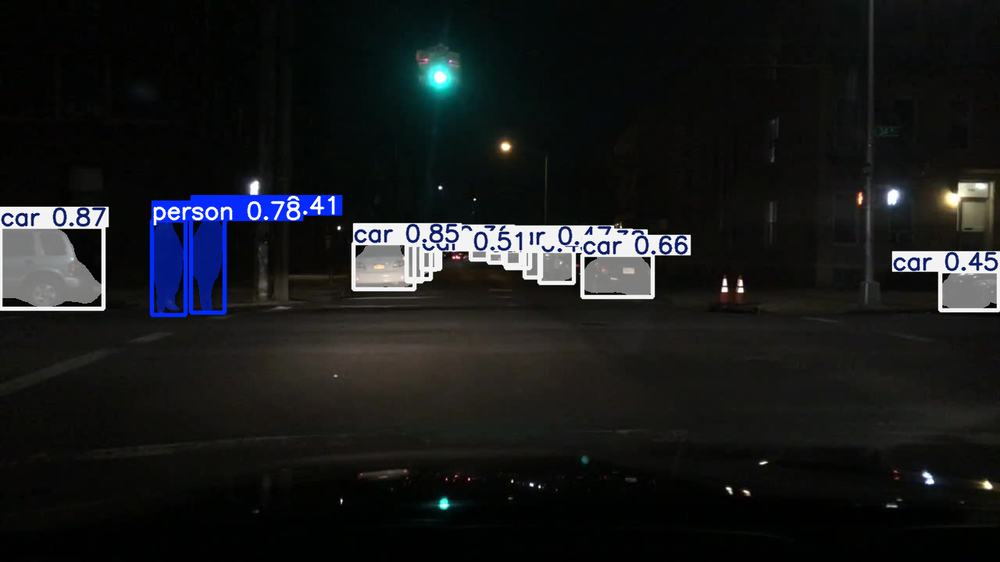
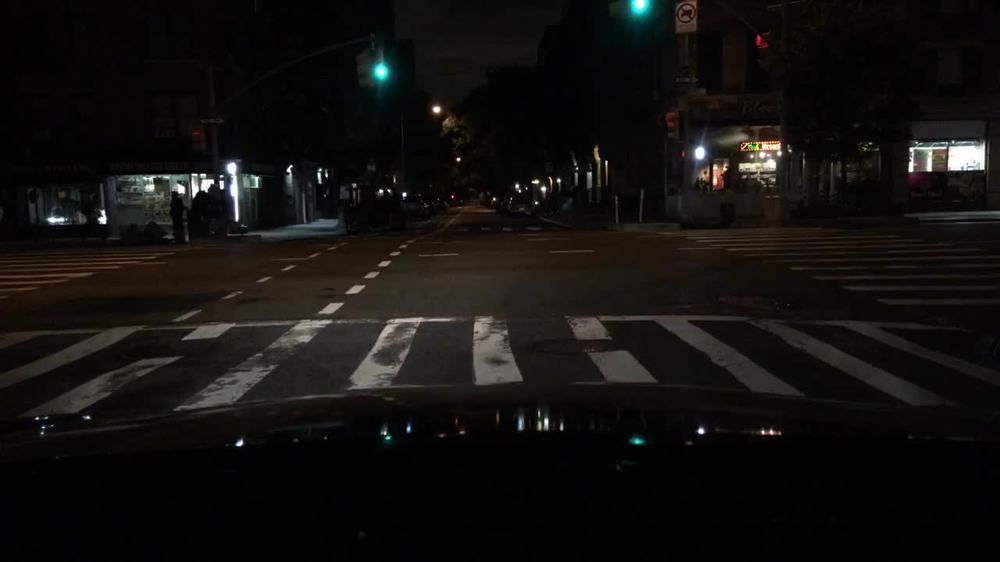
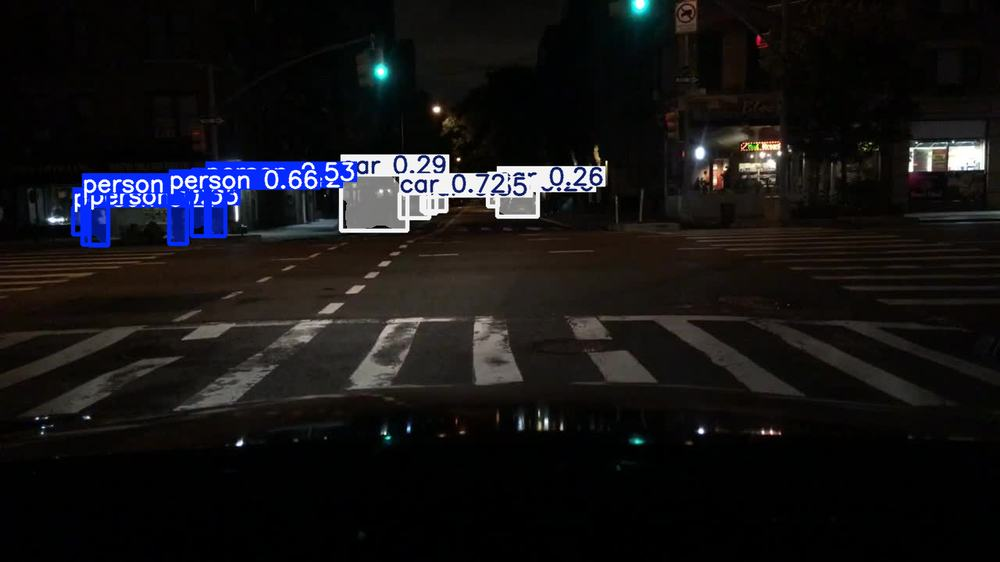


Bao cao da duoc hien thi trong output cua cell.
So byte: 1174365


In [46]:
from pathlib import Path
from IPython.display import HTML, display

# File HTML da tao truoc do
report_path = Path(
    "/kaggle/working/yolo11x_predictions_report.html"
)

if not report_path.exists():
    raise FileNotFoundError(
        f"Khong tim thay file bao cao: {report_path}"
    )

# Doc va hien thi truc tiep bao cao trong output cua cell
report_html = report_path.read_text(encoding="utf-8")

display(HTML(report_html))

print("\nBao cao da duoc hien thi trong output cua cell.")
print("So byte:", report_path.stat().st_size)